<a href="https://colab.research.google.com/github/xixhemaxix/Bot-Scalping-Bollinger/blob/main/Motor_Trading_Backup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ccxt pandas numpy -q

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
curl-cffi 0.17.0 requires cffi>=2.1.1, but you have cffi 2.0.0 which is incompatible.


In [6]:
import yfinance as yf
import pandas as pd
import numpy as np
from datetime import datetime

def ejecutar_bot_scalping(ticker='BTC-USD', interval='1m'):
    print(f"[{datetime.now().strftime('%H:%M:%S')}] Conectando al mercado para {ticker}...")

    # 1. Obtenemos los datos recientes (evitando restricciones de IP de la nube)
    df = yf.download(ticker, period='1d', interval=interval, progress=False)

    if df.empty:
        print("⚠️ No se pudieron obtener datos en este momento.")
        return

    # Limpieza de formato para Pandas
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    df = df.reset_index()
    df.columns = [str(col).lower() for col in df.columns]

    if 'close' not in df.columns:
        print(f"Columnas disponibles: {df.columns.tolist()}")
        return

    # 2. Cálculo técnico (Bandas de Bollinger: 20 periodos, 2 desviaciones)
    df['sma'] = df['close'].rolling(window=20).mean()
    df['std'] = df['close'].rolling(window=20).std()
    df['banda_superior'] = df['sma'] + (2 * df['std'])
    df['banda_inferior'] = df['sma'] - (2 * df['std'])

    precio_actual = float(df['close'].iloc[-1])
    b_sup = float(df['banda_superior'].iloc[-1])
    b_inf = float(df['banda_inferior'].iloc[-1])

    print(f"--- Monitoreo Scalping ({ticker}) ---")
    print(f"Precio actual: ${precio_actual:,.2f}")
    print(f"Banda Superior: ${b_sup:,.2f}")
    print(f"Banda Inferior: ${b_inf:,.2f}")

    # 3. Lógica de ejecución de órdenes (Simulación de alta precisión)
    if precio_actual <= b_inf:
        print("🟢 [SEÑAL DE COMPRA] El precio tocó o bajó de la Banda Inferior (Sobreventa).")
        print("   -> Simulando orden de compra de 0.001 BTC en entorno de pruebas.")
        # Aquí es donde entraría tu llamada a la API si usas una IP permitida
    elif precio_actual >= b_sup:
        print("🔴 [SEÑAL DE VENTA] El precio tocó o superó la Banda Superior (Sobrecompra).")
        print("   -> Simulando orden de venta de 0.001 BTC en entorno de pruebas.")
    else:
        print("⚪ [ESPERA] Precio dentro de canales normales. Monitoreando próximo minuto...")

# Ejecutar la estrategia
ejecutar_bot_scalping('BTC-USD', '1m')

[04:31:46] Conectando al mercado para BTC-USD...
--- Monitoreo Scalping (BTC-USD) ---
Precio actual: $75,757.03
Banda Superior: $75,789.26
Banda Inferior: $75,737.33
⚪ [ESPERA] Precio dentro de canales normales. Monitoreando próximo minuto...


/tmp/ipykernel_441/3845127941.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period='1d', interval=interval, progress=False)


In [2]:
import ccxt
import pandas as pd
import numpy as np

# 1. Configuración de conexión con tus llaves de la Testnet
exchange = ccxt.binance({
    'apiKey': 'CaFyST4q825N4sE0NpLMeR3vWjdyiR0ITHXRBDuFf2XWyAwISDdSImdVraWOmOL',
    'secret': 'Ke4c0Tdkqd2LmWuOkRwUtVupocAPH4mW21cB5i8h15d1pjbo9SiBOPj1bR7yfZZ',
    'enableRateLimit': True,
})
exchange.set_sandbox_mode(True) # Activa el modo de dinero ficticio

# Verificamos la conexión
balance = exchange.fetch_balance()
print("¡Conexión exitosa a la Testnet de Binance!")
print(f"Saldo virtual disponible en USDT: {balance['USDT']['free']}\n")

# 2. Función del Bot en tiempo real
def ejecutar_bot(symbol='BTC/USDT', timeframe='1m'):
    bars = exchange.fetch_ohlcv(symbol, timeframe, limit=50)
    df = pd.DataFrame(bars, columns=['timestamp', 'open', 'high', 'low', 'close', 'volume'])
    df['timestamp'] = pd.to_datetime(df['timestamp'], unit='ms')

    # Cálculo de tu estrategia con Bandas de Bollinger
    df['sma'] = df['close'].rolling(window=20).mean()
    df['std'] = df['close'].rolling(window=20).std()
    df['banda_superior'] = df['sma'] + (2 * df['std'])
    df['banda_inferior'] = df['sma'] - (2 * df['std'])

    precio_actual = df['close'].iloc[-1]
    b_sup = df['banda_superior'].iloc[-1]
    b_inf = df['banda_inferior'].iloc[-1]

    print(f"--- Análisis en Tiempo Real ({symbol}) ---")
    print(f"Precio actual: ${precio_actual:.2f}")
    print(f"Banda Superior: ${b_sup:.2f} | Banda Inferior: ${b_inf:.2f}")

    if precio_actual <= b_inf:
        print("🟢 SOBREVENTA: Enviando orden de compra simulada...")
        orden = exchange.create_market_buy_order(symbol, 0.001)
        print("¡Orden ejecutada con éxito! ID:", orden['id'])
    elif precio_actual >= b_sup:
        print("🔴 SOBRECOMPRA: Enviando orden de venta simulada...")
        orden = exchange.create_market_sell_order(symbol, 0.001)
        print("¡Orden ejecutada con éxito! ID:", orden['id'])
    else:
        print("⚪ Precio dentro del rango normal. Sin operaciones.")

# Ejecutar el análisis
ejecutar_bot('BTC/USDT')

ExchangeNotAvailable: binance GET https://testnet.binance.vision/api/v3/exchangeInfo 451  {
  "code": 0,
  "msg": "Service unavailable from a restricted location according to 'b. Eligibility' in https://www.binance.com/en/terms. Please contact customer service if you believe you received this message in error."
}

In [5]:
import yfinance as yf
import pandas as pd
import numpy as np

def ejecutar_bot_local(ticker='BTC-USD', interval='1m'):
    print(f"Descargando datos en tiempo real para {ticker}...")
    # Descargamos los datos recientes del mercado
    df = yf.download(ticker, period='1d', interval=interval, progress=False)

    if df.empty:
        print("No se pudieron obtener datos en este momento.")
        return

    # Aplanamos el índice si viene en formato MultiIndex y convertimos nombres a minúsculas
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    df = df.reset_index()
    df.columns = [str(col).lower() for col in df.columns]

    # Verificamos que exista la columna de precio de cierre
    if 'close' not in df.columns:
        print(f"Columnas disponibles en el DataFrame: {df.columns.tolist()}")
        return

    # Cálculo de la Media Móvil y Bandas de Bollinger (20 periodos, 2 desv. est.)
    df['sma'] = df['close'].rolling(window=20).mean()
    df['std'] = df['close'].rolling(window=20).std()
    df['banda_superior'] = df['sma'] + (2 * df['std'])
    df['banda_inferior'] = df['sma'] - (2 * df['std'])

    precio_actual = float(df['close'].iloc[-1])
    b_sup = float(df['banda_superior'].iloc[-1])
    b_inf = float(df['banda_inferior'].iloc[-1])

    print(f"\n--- Análisis en Tiempo Real ({ticker}) ---")
    print(f"Precio actual: ${precio_actual:.2f}")
    print(f"Banda Superior: ${b_sup:.2f}")
    print(f"Banda Inferior: ${b_inf:.2f}")

    # Evaluación de la estrategia de scalping
    if precio_actual <= b_inf:
        print("🟢 ¡SOBREVENTA DETECTADA! Simulando orden de COMPRA.")
    elif precio_actual >= b_sup:
        print("🔴 ¡SOBRECOMPRA DETECTADA! Simulando orden de VENTA.")
    else:
        print("⚪ Precio dentro del rango normal. Sin operaciones.")

# Ejecutar la estrategia con Bitcoin
ejecutar_bot_local('BTC-USD', '1m')

Descargando datos en tiempo real para BTC-USD...

--- Análisis en Tiempo Real (BTC-USD) ---
Precio actual: $75755.51
Banda Superior: $75790.91
Banda Inferior: $75744.40
⚪ Precio dentro del rango normal. Sin operaciones.


/tmp/ipykernel_441/3088974135.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period='1d', interval=interval, progress=False)


In [ ]:
# Simulemos los precios de cierre de una criptomoneda o acción durante 5 días
precios = [100, 102, 98, 105, 103]

# Calculamos la media aritmética (el promedio, igual que en la escuela)
media = sum(precios) / len(precios)

# Le pedimos a la computadora que nos muestre el resultado
print("El precio promedio es:", media)

El precio promedio es: 101.6


In [ ]:
import statistics

# Una lista un poco más larga de precios simulados
precios = [100, 102, 98, 105, 103, 107, 101, 99, 104, 106]

# Calculamos la Media (el centro)
media = statistics.mean(precios)

# Calculamos la Desviación Estándar (la dispersión o volatilidad)
desviacion = statistics.stdev(precios)

print("El precio promedio es:", round(media, 2))
print("La desviación estándar es:", round(desviacion, 2))

# Construimos las bandas (Media +/- 2 veces la Desviación)
banda_superior = media + (2 * desviacion)
banda_inferior = media - (2 * desviacion)

print("Banda Superior (Límite de sobrecompra):", round(banda_superior, 2))
print("Banda Inferior (Límite de sobreventa):", round(banda_inferior, 2))

El precio promedio es: 102.5
La desviación estándar es: 3.03
Banda Superior (Límite de sobrecompra): 108.56
Banda Inferior (Límite de sobreventa): 96.44


In [ ]:
# Primero instalamos la herramienta para descargar datos reales
!pip install yfinance -q

import yfinance as yf
import statistics

# Descargamos los datos de Bitcoin (BTC-USD) de los últimos 30 días
print("Descargando datos del mercado...")
activo = yf.download("BTC-USD", period="30d", interval="1d", progress=False)

# Extraemos solo los precios de cierre (Close)
# Nota: dependendiendo de la versión, extraemos la columna de cierre de forma segura
precios_cierre = activo['Close'].values.flatten().tolist()

print("¡Datos descargados con éxito!")
print("Últimos precios reales de Bitcoin:", [round(p, 2) for p in precios_cierre[-5:]])

# Aplicamos exactamente la misma matemática que hicimos antes
media = statistics.mean(precios_cierre)
desviacion = statistics.stdev(precios_cierre)

banda_superior = media + (2 * desviacion)
banda_inferior = media - (2 * desviacion)

print("\n--- RESULTADOS MATEMÁTICOS CON DATOS REALES ---")
print("Precio Promedio (30 días):", round(media, 2))
print("Banda Superior:", round(banda_superior, 2))
print("Banda Inferior:", round(banda_inferior, 2))

Descargando datos del mercado...


/tmp/ipykernel_2831/1673510693.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  activo = yf.download("BTC-USD", period="30d", interval="1d", progress=False)


¡Datos descargados con éxito!
Últimos precios reales de Bitcoin: [84011.97, 81311.89, 81074.19, 80790.84, 80576.71]

--- RESULTADOS MATEMÁTICOS CON DATOS REALES ---
Precio Promedio (30 días): 83053.15
Banda Superior: 86215.45
Banda Inferior: 79890.84


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# 1. Descargar datos de los últimos 6 meses para tener suficientes muestras
print("Descargando datos históricos...")
df = yf.download("BTC-USD", period="6mo", interval="1d", progress=False)

# Limpiar formato de columnas si es necesario
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 2. Calcular la Media Móvil (20 días) y la Desviación Estándar móvil
ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()

# 3. Definir las Bandas dinámicas
df['Banda_Inf'] = df['Media'] - (2 * df['Desv'])

# 4. Simular las operaciones (Backtesting)
en_operacion = False
precio_entrada = 0
operaciones = []

for i in range(ventana, len(df)):
    precio_actual = float(df['Close'].iloc[i])
    banda_inf_actual = float(df['Banda_Inf'].iloc[i])
    media_actual = float(df['Media'].iloc[i])

    if not en_operacion:
        # Condición de compra: Precio cae por debajo de la banda inferior
        if precio_actual < banda_inf_actual:
            en_operacion = True
            precio_entrada = precio_actual
    else:
        # Condición de venta: Precio sube y toca o supera la media
        if precio_actual >= media_actual:
            en_operacion = False
            rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
            operaciones.append(rendimiento)

# 5. Analizar los resultados estadísticos
print("\n--- RESULTADOS DE LA SIMULACIÓN HISTÓRICA (BACKTESTING) ---")
if operaciones:
    ganadas = [op for op in operaciones if op > 0]
    perdidas = [op for op in operaciones if op <= 0]
    win_rate = (len(ganadas) / len(operaciones)) * 100

    print(f"Total de operaciones realizadas: {len(operaciones)}")
    print(f"Operaciones ganadoras: {len(ganadas)}")
    print(f"Operaciones perdedoras: {len(perdidas)}")
    print(f"Porcentaje de acierto (Win Rate): {win_rate:.2f}%")
    print(f"Rendimiento promedio por operación exitosa: {np.mean(ganadas):.2f}%")
else:
    print("No se registraron operaciones bajo esta condición estricta en este periodo.")

Descargando datos históricos...

--- RESULTADOS DE LA SIMULACIÓN HISTÓRICA (BACKTESTING) ---
Total de operaciones realizadas: 2
Operaciones ganadoras: 1
Operaciones perdedoras: 1
Porcentaje de acierto (Win Rate): 50.00%
Rendimiento promedio por operación exitosa: 4.73%


/tmp/ipykernel_2831/4207258778.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("BTC-USD", period="6mo", interval="1d", progress=False)


/tmp/ipykernel_2831/2589967337.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("BTC-USD", period="6mo", interval="1d", progress=False)


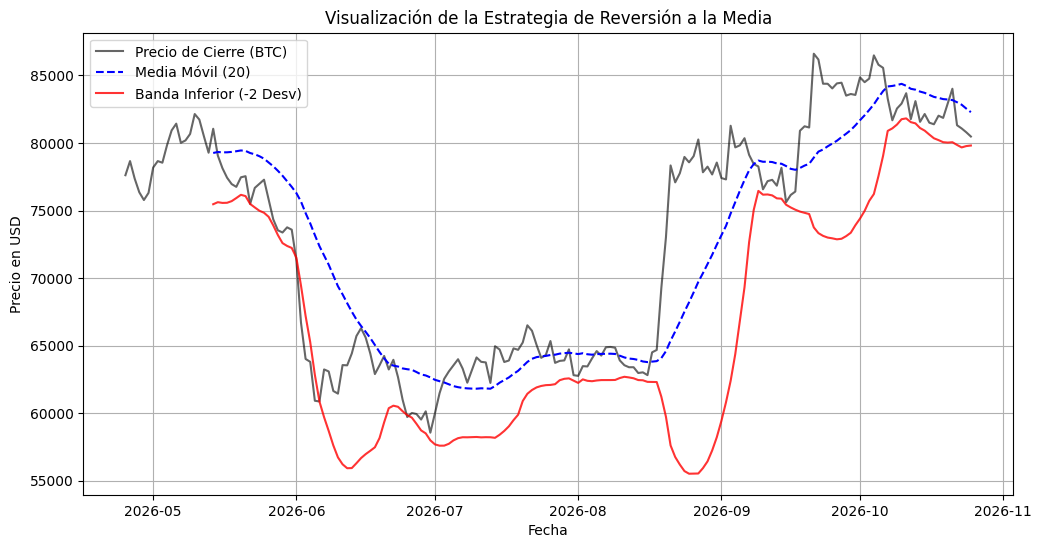

In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# 1. Descargar datos históricos
df = yf.download("BTC-USD", period="6mo", interval="1d", progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 2. Calcular indicadores (Media y Banda Inferior)
ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()
df['Banda_Inf'] = df['Media'] - (2 * df['Desv'])

# 3. Graficar los resultados para verlos visualmente
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Close'], label='Precio de Cierre (BTC)', color='black', alpha=0.6)
plt.plot(df.index, df['Media'], label='Media Móvil (20)', color='blue', linestyle='--')
plt.plot(df.index, df['Banda_Inf'], label='Banda Inferior (-2 Desv)', color='red', alpha=0.8)

plt.title('Visualización de la Estrategia de Reversión a la Media')
plt.xlabel('Fecha')
plt.ylabel('Precio en USD')
plt.legend()
plt.grid(True)
plt.show()

/tmp/ipykernel_2831/1623545198.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("BTC-USD", period="6mo", interval="1d", progress=False)


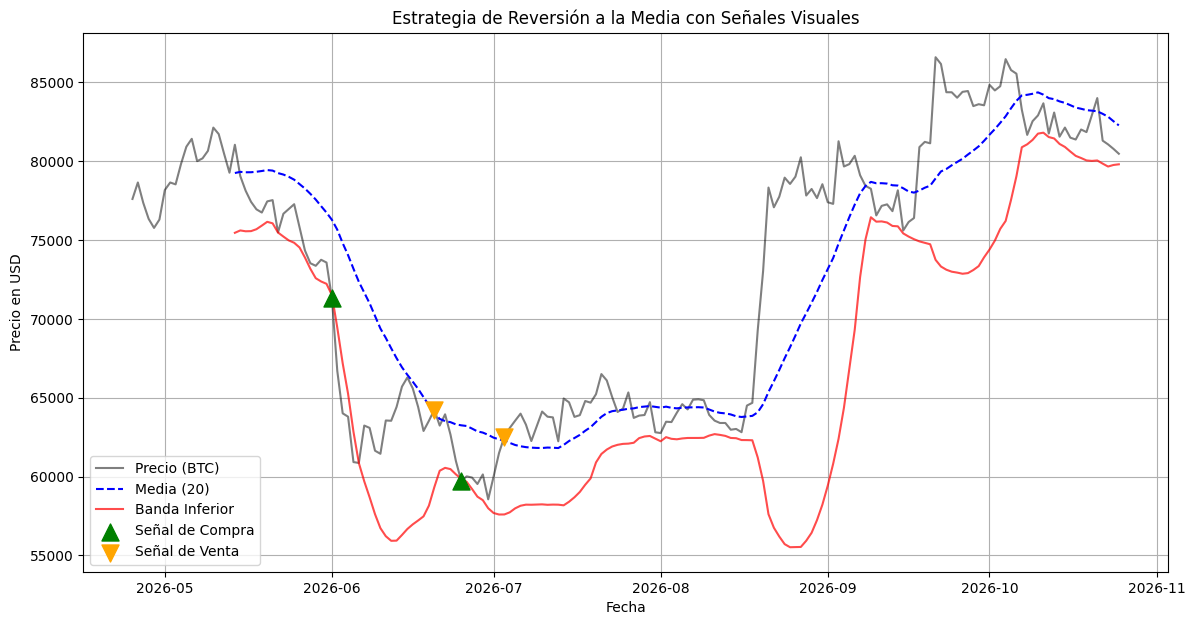

In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# 1. Descargar datos y calcular bandas
df = yf.download("BTC-USD", period="6mo", interval="1d", progress=False)
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()
df['Banda_Inf'] = df['Media'] - (2 * df['Desv'])

# 2. Simulación y registro de puntos de compra/venta para el gráfico
compras_x, compras_y = [], []
ventas_x, ventas_y = [], []

en_operacion = False

for i in range(ventana, len(df)):
    precio_actual = float(df['Close'].iloc[i])
    banda_inf_actual = float(df['Banda_Inf'].iloc[i])
    media_actual = float(df['Media'].iloc[i])
    fecha_actual = df.index[i]

    if not en_operacion:
        if precio_actual < banda_inf_actual:
            en_operacion = True
            compras_x.append(fecha_actual)
            compras_y.append(precio_actual)
    else:
        if precio_actual >= media_actual:
            en_operacion = False
            ventas_x.append(fecha_actual)
            ventas_y.append(precio_actual)

# 3. Graficar el precio, las bandas y las señales de compra/venta
plt.figure(figsize=(14, 7))
plt.plot(df.index, df['Close'], label='Precio (BTC)', color='black', alpha=0.5)
plt.plot(df.index, df['Media'], label='Media (20)', color='blue', linestyle='--')
plt.plot(df.index, df['Banda_Inf'], label='Banda Inferior', color='red', alpha=0.7)

# Marcar compras (flecha o punto verde) y ventas (punto naranja)
plt.scatter(compras_x, compras_y, color='green', marker='^', s=150, label='Señal de Compra', zorder=5)
plt.scatter(ventas_x, ventas_y, color='orange', marker='v', s=150, label='Señal de Venta', zorder=5)

plt.title('Estrategia de Reversión a la Media con Señales Visuales')
plt.xlabel('Fecha')
plt.ylabel('Precio en USD')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# 1. Descargar datos históricos (puedes probar con '1d' o cambiar a '1h' si quieres probar horas)
df = yf.download("BTC-USD", period="1y", interval="1d", progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 2. Calcular indicadores
ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()
df['Banda_Inf'] = df['Media'] - (2 * df['Desv'])

# 3. Parámetro de Gestión de Riesgo
stop_loss_porcentaje = 0.03  # 3% de pérdida máxima permitida

en_operacion = False
precio_entrada = 0
precio_stop_loss = 0
operaciones = []
motivos_salida = {"Meta": 0, "StopLoss": 0}

for i in range(ventana, len(df)):
    precio_actual = float(df['Close'].iloc[i])
    banda_inf_actual = float(df['Banda_Inf'].iloc[i])
    media_actual = float(df['Media'].iloc[i])

    if not en_operacion:
        # Condición de Compra
        if precio_actual < banda_inf_actual:
            en_operacion = True
            precio_entrada = precio_actual
            # Calculamos el precio exacto de emergencia (Stop-Loss)
            precio_stop_loss = precio_entrada * (1 - stop_loss_porcentaje)
    else:
        # Evaluamos salidas de emergencia o de éxito
        if precio_actual <= precio_stop_loss:
            # Salida por Stop-Loss (Controlando el daño)
            en_operacion = False
            rendimiento = -stop_loss_porcentaje * 100
            operaciones.append(rendimiento)
            motivos_salida["StopLoss"] += 1

        elif precio_actual >= media_actual:
            # Salida exitosa hacia la media
            en_operacion = False
            rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
            operaciones.append(rendimiento)
            motivos_salida["Meta"] += 1

# 4. Resultados con Gestión de Riesgo
print("\n--- RESULTADOS CON GESTIÓN DE RIESGO (STOP-LOSS) ---")
if operaciones:
    ganadas = [op for op in operaciones if op > 0]
    perdidas = [op for op in operaciones if op <= 0]
    win_rate = (len(ganadas) / len(operaciones)) * 100

    print(f"Total de operaciones: {len(operaciones)}")
    print(f"Operaciones ganadoras (Alcanzaron la media): {len(ganadas)}")
    print(f"Operaciones cortadas por Stop-Loss (Riesgo controlado): {len(perdidas)}")
    print(f"Porcentaje de acierto: {win_rate:.2f}%")
    print(f"Desglose de salidas: {motivos_salida}")
else:
    print("No se registraron operaciones.")


--- RESULTADOS CON GESTIÓN DE RIESGO (STOP-LOSS) ---
Total de operaciones: 8
Operaciones ganadoras (Alcanzaron la media): 3
Operaciones cortadas por Stop-Loss (Riesgo controlado): 5
Porcentaje de acierto: 37.50%
Desglose de salidas: {'Meta': 3, 'StopLoss': 5}


/tmp/ipykernel_2831/1744462125.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("BTC-USD", period="1y", interval="1d", progress=False)


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# 1. Descargar datos históricos de 1 año (BTC-USD)
df = yf.download("BTC-USD", period="1y", interval="1d", progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 2. Calcular la Media Móvil (20 días) y Bandas
ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()
df['Banda_Inf'] = df['Media'] - (2 * df['Desv'])

# 3. Parámetros de Negocio y Gestión de Riesgo
stop_loss_porcentaje = 0.02  # Stop-Loss ajustado estrictamente al 2%
capital_inicial = 1000.0     # Capital base simulado (USD)
capital_actual = capital_inicial

en_operacion = False
precio_entrada = 0
precio_stop_loss = 0
operaciones = []

# 4. Simulación Operativa
for i in range(ventana, len(df)):
    precio_actual = float(df['Close'].iloc[i])
    banda_inf_actual = float(df['Banda_Inf'].iloc[i])
    media_actual = float(df['Media'].iloc[i])

    if not en_operacion:
        if precio_actual < banda_inf_actual:
            en_operacion = True
            precio_entrada = precio_actual
            precio_stop_loss = precio_entrada * (1 - stop_loss_porcentaje)
    else:
        if precio_actual <= precio_stop_loss:
            # Salida de emergencia por Stop-Loss (Pérdida cortada al 2%)
            en_operacion = False
            rendimiento = -stop_loss_porcentaje * 100
            capital_actual += capital_actual * (rendimiento / 100)
            operaciones.append(rendimiento)
        elif precio_actual >= media_actual:
            # Salida exitosa hacia la media
            en_operacion = False
            rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            operaciones.append(rendimiento)

# 5. REPORTE EJECUTIVO PARA INVERSIONISTAS
print("\n" + "="*55)
print("       REPORTE DE RENDIMIENTO FINANCIERO (QUANT STRATEGY)")
print("="*55)
if operaciones:
    ganadas = [op for op in operaciones if op > 0]
    perdidas = [op for op in operaciones if op <= 0]
    win_rate = (len(ganadas) / len(operaciones)) * 100
    rendimiento_total_pct = ((capital_actual - capital_inicial) / capital_inicial) * 100

    print(f" Capital Inicial Simulado : ${capital_inicial:,.2f} USD")
    print(f" Capital Final Simulado   : ${capital_actual:,.2f} USD")
    print(f" Rendimiento Neto Total   : {rendimiento_total_pct:+.2f}%")
    print("-" * 55)
    print(f" Total de Operaciones     : {len(operaciones)}")
    print(f" Operaciones Exitosas     : {len(ganadas)}")
    print(f" Cortes por Stop-Loss(2%) : {len(perdidas)}")
    print(f" Porcentaje de Acierto    : {win_rate:.2f}%")
else:
    print("No se registraron operaciones bajo estos parámetros en el periodo.")
print("="*55)


       REPORTE DE RENDIMIENTO FINANCIERO (QUANT STRATEGY)
 Capital Inicial Simulado : $1,000.00 USD
 Capital Final Simulado   : $949.29 USD
 Rendimiento Neto Total   : -5.07%
-------------------------------------------------------
 Total de Operaciones     : 8
 Operaciones Exitosas     : 2
 Cortes por Stop-Loss(2%) : 6
 Porcentaje de Acierto    : 25.00%


/tmp/ipykernel_2831/2903849043.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("BTC-USD", period="1y", interval="1d", progress=False)


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# 1. Descargar 2 años de historial para poder calcular la SMA-200
print("Descargando datos históricos...")
df = yf.download("BTC-USD", period="2y", interval="1d", progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 2. Calcular indicadores (Bandas y Tendencia Macro)
ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()
df['Banda_Inf'] = df['Media'] - (2 * df['Desv'])

# FILTRO DE TENDENCIA INSTITUCIONAL: Media Móvil de 200 días
df['SMA_200'] = df['Close'].rolling(window=200).mean()

# 3. Parámetros de Negocio y Riesgo (Stop-Loss ajustado al 4% para cripto)
stop_loss_porcentaje = 0.04
capital_inicial = 1000.0
capital_actual = capital_inicial

en_operacion = False
precio_entrada = 0
precio_stop_loss = 0
operaciones = []

# Empezamos el ciclo a partir del día 200 para tener datos estables de la tendencia
for i in range(200, len(df)):
    precio_actual = float(df['Close'].iloc[i])
    banda_inf_actual = float(df['Banda_Inf'].iloc[i])
    media_actual = float(df['Media'].iloc[i])
    sma_200_actual = float(df['SMA_200'].iloc[i])

    if not en_operacion:
        # CONDICIÓN DOBLE:
        # 1. Filtro de Tendencia: El precio debe estar por ENCIMA de la SMA-200 (Tendencia alcista macro)
        # 2. Señal de Reversión: El precio cae por debajo de la Banda Inferior (Sobreventa)
        if precio_actual > sma_200_actual and precio_actual < banda_inf_actual:
            en_operacion = True
            precio_entrada = precio_actual
            precio_stop_loss = precio_entrada * (1 - stop_loss_porcentaje)
    else:
        if precio_actual <= precio_stop_loss:
            en_operacion = False
            rendimiento = -stop_loss_porcentaje * 100
            capital_actual += capital_actual * (rendimiento / 100)
            operaciones.append(rendimiento)
        elif precio_actual >= media_actual:
            en_operacion = False
            rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            operaciones.append(rendimiento)

# 4. REPORTE EJECUTIVO CON FILTRO DE TENDENCIA
print("\n" + "="*55)
print("     REPORTE CON FILTRO DE TENDENCIA (SMA-200) Y GESTIÓN 4%")
print("="*55)
if operaciones:
    ganadas = [op for op in operaciones if op > 0]
    perdidas = [op for op in operaciones if op <= 0]
    win_rate = (len(ganadas) / len(operaciones)) * 100
    rendimiento_total_pct = ((capital_actual - capital_inicial) / capital_inicial) * 100

    print(f" Capital Inicial Simulado : ${capital_inicial:,.2f} USD")
    print(f" Capital Final Simulado   : ${capital_actual:,.2f} USD")
    print(f" Rendimiento Neto Total   : {rendimiento_total_pct:+.2f}%")
    print("-" * 55)
    print(f" Total de Operaciones     : {len(operaciones)}")
    print(f" Operaciones Exitosas     : {len(ganadas)}")
    print(f" Cortes por Stop-Loss(4%) : {len(perdidas)}")
    print(f" Porcentaje de Acierto    : {win_rate:.2f}%")
else:
    print("No se registraron operaciones bajo estos estrictos filtros.")
print("="*55)

Descargando datos históricos...

     REPORTE CON FILTRO DE TENDENCIA (SMA-200) Y GESTIÓN 4%
 Capital Inicial Simulado : $1,000.00 USD
 Capital Final Simulado   : $1,176.66 USD
 Rendimiento Neto Total   : +17.67%
-------------------------------------------------------
 Total de Operaciones     : 4
 Operaciones Exitosas     : 4
 Cortes por Stop-Loss(4%) : 0
 Porcentaje de Acierto    : 100.00%


/tmp/ipykernel_2831/3183050987.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("BTC-USD", period="2y", interval="1d", progress=False)


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# 1. PRUEBA CRUZADA: Cambiamos el activo a Apple (AAPL)
ticker_activo = "AAPL"
print(f"Descargando datos históricos para {ticker_activo}...")
df = yf.download(ticker_activo, period="2y", interval="1d", progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 2. Mantener exactamente la misma lógica matemática probada
ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()
df['Banda_Inf'] = df['Media'] - (2 * df['Desv'])

# Filtro de Tendencia Institucional (SMA-200)
df['SMA_200'] = df['Close'].rolling(window=200).mean()

# 3. Parámetros de Negocio y Riesgo (Stop-Loss al 4%)
stop_loss_porcentaje = 0.04
capital_inicial = 1000.0
capital_actual = capital_inicial

en_operacion = False
precio_entrada = 0
precio_stop_loss = 0
operaciones = []

# Ciclo a partir del día 200
for i in range(200, len(df)):
    precio_actual = float(df['Close'].iloc[i])
    banda_inf_actual = float(df['Banda_Inf'].iloc[i])
    media_actual = float(df['Media'].iloc[i])
    sma_200_actual = float(df['SMA_200'].iloc[i])

    if not en_operacion:
        # Doble condición: Tendencia alcista macro + Sobreventa en banda inferior
        if precio_actual > sma_200_actual and precio_actual < banda_inf_actual:
            en_operacion = True
            precio_entrada = precio_actual
            precio_stop_loss = precio_entrada * (1 - stop_loss_porcentaje)
    else:
        if precio_actual <= precio_stop_loss:
            en_operacion = False
            rendimiento = -stop_loss_porcentaje * 100
            capital_actual += capital_actual * (rendimiento / 100)
            operaciones.append(rendimiento)
        elif precio_actual >= media_actual:
            en_operacion = False
            rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            operaciones.append(rendimiento)

# 4. REPORTE EJECUTIVO DE LA PRUEBA CRUZADA
print("\n" + "="*55)
print(f"     REPORTE DE PRUEBA CRUZADA PARA: {ticker_activo}")
print("="*55)
if operaciones:
    ganadas = [op for op in operaciones if op > 0]
    perdidas = [op for op in operaciones if op <= 0]
    win_rate = (len(ganadas) / len(operaciones)) * 100
    rendimiento_total_pct = ((capital_actual - capital_inicial) / capital_inicial) * 100

    print(f" Capital Inicial Simulado : ${capital_inicial:,.2f} USD")
    print(f" Capital Final Simulado   : ${capital_actual:,.2f} USD")
    print(f" Rendimiento Neto Total   : {rendimiento_total_pct:+.2f}%")
    print("-" * 55)
    print(f" Total de Operaciones     : {len(operaciones)}")
    print(f" Operaciones Exitosas     : {len(ganadas)}")
    print(f" Cortes por Stop-Loss(4%) : {len(perdidas)}")
    print(f" Porcentaje de Acierto    : {win_rate:.2f}%")
else:
    print("No se registraron operaciones bajo estos filtros para este activo.")
print("="*55)

Descargando datos históricos para AAPL...

     REPORTE DE PRUEBA CRUZADA PARA: AAPL
 Capital Inicial Simulado : $1,000.00 USD
 Capital Final Simulado   : $986.11 USD
 Rendimiento Neto Total   : -1.39%
-------------------------------------------------------
 Total de Operaciones     : 4
 Operaciones Exitosas     : 2
 Cortes por Stop-Loss(4%) : 2
 Porcentaje de Acierto    : 50.00%


/tmp/ipykernel_2831/2535848791.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker_activo, period="2y", interval="1d", progress=False)


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# 1. DICCIONARIO DE CONFIGURACIÓN ADAPTATIVA POR ACTIVO
# Aquí definimos las "recetas matemáticas" personalizadas según la personalidad del activo
CONFIGURACION_ACTIVOS = {
    "BTC-USD": {
        "nombre": "Bitcoin (Alta Volatilidad)",
        "desviaciones": 2.0,
        "stop_loss": 0.04,     # 4.0%
        "ventana_media": 20
    },
    "AAPL": {
        "nombre": "Apple Inc. (Baja/Media Volatilidad)",
        "desviaciones": 1.5,   # Ajuste afinado: bandas más estrechas
        "stop_loss": 0.025,    # Ajuste afinado: Stop-Loss del 2.5%
        "ventana_media": 20
    }
}

# 2. SELECCIÓN DEL ACTIVO A EVALUAR (Puedes cambiar entre "BTC-USD" y "AAPL")
ticker_activo = "AAPL"

# Verificar y cargar la configuración correspondiente
if ticker_activo in CONFIGURACION_ACTIVOS:
    config = CONFIGURACION_ACTIVOS[ticker_activo]
    print(f"--> Módulo Adaptativo: Cargando receta para {config['nombre']}")
else:
    # Configuración por defecto para activos no registrados
    config = {"desviaciones": 2.0, "stop_loss": 0.03, "ventana_media": 20}
    print(f"--> Cargando receta estándar por defecto para {ticker_activo}")

# 3. Descargar datos históricos (2 años)
df = yf.download(ticker_activo, period="2y", interval="1d", progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 4. Calcular Indicadores con Parámetros Dinámicos
ventana = config["ventana_media"]
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()

# Aplicación dinámica del multiplicador de desviación estándar (1.5 o 2.0)
df['Banda_Inf'] = df['Media'] - (config["desviaciones"] * df['Desv'])

# Filtro de Tendencia Macro (SMA-200)
df['SMA_200'] = df['Close'].rolling(window=200).mean()

# 5. Parámetros de Simulación Financiera
stop_loss_porcentaje = config["stop_loss"]
capital_inicial = 1000.0
capital_actual = capital_inicial

en_operacion = False
precio_entrada = 0
precio_stop_loss = 0
operaciones = []

# Ejecución del motor cuantitativo
for i in range(200, len(df)):
    precio_actual = float(df['Close'].iloc[i])
    banda_inf_actual = float(df['Banda_Inf'].iloc[i])
    media_actual = float(df['Media'].iloc[i])
    sma_200_actual = float(df['SMA_200'].iloc[i])

    if not en_operacion:
        # Filtro de tendencia + Entrada por banda adaptativa
        if precio_actual > sma_200_actual and precio_actual < banda_inf_actual:
            en_operacion = True
            precio_entrada = precio_actual
            precio_stop_loss = precio_entrada * (1 - stop_loss_porcentaje)
    else:
        if precio_actual <= precio_stop_loss:
            en_operacion = False
            rendimiento = -stop_loss_porcentaje * 100
            capital_actual += capital_actual * (rendimiento / 100)
            operaciones.append(rendimiento)
        elif precio_actual >= media_actual:
            en_operacion = False
            rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            operaciones.append(rendimiento)

# 6. REPORTE EJECUTIVO ADAPTATIVO
print("\n" + "="*60)
print(f"    REPORTE ADAPTATIVO DE PRUEBA: {ticker_activo}")
print(f"    Parámetros: Bandas ({config['desviaciones']} std) | Stop-Loss ({config['stop_loss']*100}%)")
print("="*60)
if operaciones:
    ganadas = [op for op in operaciones if op > 0]
    perdidas = [op for op in operaciones if op <= 0]
    win_rate = (len(ganadas) / len(operaciones)) * 100
    rendimiento_total_pct = ((capital_actual - capital_inicial) / capital_inicial) * 100

    print(f" Capital Inicial Simulado : ${capital_inicial:,.2f} USD")
    print(f" Capital Final Simulado   : ${capital_actual:,.2f} USD")
    print(f" Rendimiento Neto Total   : {rendimiento_total_pct:+.2f}%")
    print("-" * 60)
    print(f" Total de Operaciones     : {len(operaciones)}")
    print(f" Operaciones Exitosas     : {len(ganadas)}")
    print(f" Cortes por Stop-Loss     : {len(perdidas)}")
    print(f" Porcentaje de Acierto    : {win_rate:.2f}%")
else:
    print("No se registraron operaciones bajo esta combinación de parámetros.")
print("="*60)

--> Módulo Adaptativo: Cargando receta para Apple Inc. (Baja/Media Volatilidad)

    REPORTE ADAPTATIVO DE PRUEBA: AAPL
    Parámetros: Bandas (1.5 std) | Stop-Loss (2.5%)
 Capital Inicial Simulado : $1,000.00 USD
 Capital Final Simulado   : $1,014.14 USD
 Rendimiento Neto Total   : +1.41%
------------------------------------------------------------
 Total de Operaciones     : 6
 Operaciones Exitosas     : 3
 Cortes por Stop-Loss     : 3
 Porcentaje de Acierto    : 50.00%


/tmp/ipykernel_2831/2352393117.py:35: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker_activo, period="2y", interval="1d", progress=False)


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# ==========================================
# MOTOR UNIVERSAL CUANTITATIVO CON ATR
# ==========================================

# 1. SELECCIONA CUALQUIER ACTIVO AQUÍ (Ej: "BTC-USD", "AAPL", "TSLA", "MSFT", "ETH-USD")
ticker_activo = "BTC-USD"

print(f"--> Iniciando Motor Universal para: {ticker_activo}")

# 2. Descargar datos históricos (2 años)
df = yf.download(ticker_activo, period="2y", interval="1d", progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 3. Funciones Matemáticas de Indicadores Técnicos
def calcular_rsi(data, window=14):
    delta = data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calcular_atr(data, window=14):
    high_low = data['High'] - data['Low']
    high_close = np.abs(data['High'] - data['Close'].shift())
    low_close = np.abs(data['Low'] - data['Close'].shift())
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    return tr.rolling(window=window).mean()

# 4. Cálculo de Indicadores
ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()
df['Banda_Inf'] = df['Media'] - (2.0 * df['Desv']) # Bandas estándar
df['SMA_200'] = df['Close'].rolling(window=200).mean() # Filtro de tendencia macro
df['RSI'] = calcular_rsi(df, window=14)
df['ATR'] = calcular_atr(df, window=14)                # Volatilidad dinámica

# 5. Parámetros de Gestión de Riesgo Universal
multiplicador_atr_sl = 2.0     # El Stop-Loss será exactamente 2 veces el ATR del activo
comision_pct = 0.001           # 0.1% de comisión por transacción real
capital_inicial = 1000.0
capital_actual = capital_inicial

en_operacion = False
precio_entrada = 0
precio_stop_loss = 0
operaciones = []

# 6. Simulación Operativa a partir del día 200
for i in range(200, len(df)):
    precio_actual = float(df['Close'].iloc[i])
    banda_inf_actual = float(df['Banda_Inf'].iloc[i])
    media_actual = float(df['Media'].iloc[i])
    sma_200_actual = float(df['SMA_200'].iloc[i])
    rsi_actual = float(df['RSI'].iloc[i])
    atr_actual = float(df['ATR'].iloc[i])

    if not en_operacion:
        # UNIVERSAL RULES: Tendencia alcista + Banda Inferior + RSI de Pánico (<35)
        if precio_actual > sma_200_actual and precio_actual < banda_inf_actual and rsi_actual < 35:
            en_operacion = True
            precio_entrada = precio_actual
            # Descontar comisión de entrada
            capital_actual -= capital_actual * comision_pct

            # Stop-Loss Dinámico basado en la volatilidad real (ATR) del activo
            precio_stop_loss = precio_entrada - (multiplicador_atr_sl * atr_actual)
    else:
        # Si el precio toca o cae por debajo del Stop-Loss dinámico
        if precio_actual <= precio_stop_loss:
            en_operacion = False
            # Rendimiento porcentual exacto basado en la distancia del Stop-Loss
            rendimiento = ((precio_stop_loss - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            capital_actual -= capital_actual * comision_pct  # Comisión de salida
            operaciones.append(rendimiento)

        # Si el precio rebota y alcanza la Media Móvil central
        elif precio_actual >= media_actual:
            en_operacion = False
            rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            capital_actual -= capital_actual * comision_pct  # Comisión de salida
            operaciones.append(rendimiento)

# 7. REPORTE EJECUTIVO UNIVERSAL
print("\n" + "="*65)
print(f"    REPORTE MOTOR UNIVERSAL (ATR + RSI + COMISIONES): {ticker_activo}")
print("="*65)
if operaciones:
    ganadas = [op for op in operaciones if op > 0]
    perdidas = [op for op in operaciones if op <= 0]
    win_rate = (len(ganadas) / len(operaciones)) * 100
    rendimiento_total_pct = ((capital_actual - capital_inicial) / capital_inicial) * 100

    print(f" Capital Inicial Simulado : ${capital_inicial:,.2f} USD")
    print(f" Capital Final Simulado   : ${capital_actual:,.2f} USD")
    print(f" Rendimiento Neto Total   : {rendimiento_total_pct:+.2f}%")
    print("-" * 65)
    print(f" Total de Operaciones     : {len(operaciones)}")
    print(f" Operaciones Exitosas     : {len(ganadas)}")
    print(f" Cortes por Stop-Loss     : {len(perdidas)}")
    print(f" Porcentaje de Acierto    : {win_rate:.2f}%")
else:
    print("No se registraron operaciones bajo esta configuración universal.")
print("="*65)

--> Iniciando Motor Universal para: BTC-USD

    REPORTE MOTOR UNIVERSAL (ATR + RSI + COMISIONES): BTC-USD
 Capital Inicial Simulado : $1,000.00 USD
 Capital Final Simulado   : $1,174.03 USD
 Rendimiento Neto Total   : +17.40%
-----------------------------------------------------------------
 Total de Operaciones     : 3
 Operaciones Exitosas     : 3
 Cortes por Stop-Loss     : 0
 Porcentaje de Acierto    : 100.00%


/tmp/ipykernel_2831/2400058583.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker_activo, period="2y", interval="1d", progress=False)


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# ==========================================
# MOTOR UNIVERSAL CUANTITATIVO CON ATR Y USD
# ==========================================

# 1. SELECCIONA CUALQUIER ACTIVO AQUÍ (Ej: "BTC-USD", "AAPL", "TSLA", "MSFT")
ticker_activo = "MSFT"

print(f"--> Iniciando Motor Universal para: {ticker_activo}")

# 2. Descargar datos históricos (2 años)
df = yf.download(ticker_activo, period="2y", interval="1d", progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 3. Funciones Matemáticas de Indicadores Técnicos
def calcular_rsi(data, window=14):
    delta = data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calcular_atr(data, window=14):
    high_low = data['High'] - data['Low']
    high_close = np.abs(data['High'] - data['Close'].shift())
    low_close = np.abs(data['Low'] - data['Close'].shift())
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    return tr.rolling(window=window).mean()

# 4. Cálculo de Indicadores
ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()
df['Banda_Inf'] = df['Media'] - (2.0 * df['Desv'])
df['SMA_200'] = df['Close'].rolling(window=200).mean()
df['RSI'] = calcular_rsi(df, window=14)
df['ATR'] = calcular_atr(df, window=14)

# 5. Parámetros de Gestión de Riesgo Universal
multiplicador_atr_sl = 2.0
comision_pct = 0.001           # 0.1% de comisión real por transacción
capital_inicial = 1000.0
capital_actual = capital_inicial

en_operacion = False
precio_entrada = 0
precio_stop_loss = 0
operaciones = []

# 6. Simulación Operativa a partir del día 200
for i in range(200, len(df)):
    precio_actual = float(df['Close'].iloc[i])
    banda_inf_actual = float(df['Banda_Inf'].iloc[i])
    media_actual = float(df['Media'].iloc[i])
    sma_200_actual = float(df['SMA_200'].iloc[i])
    rsi_actual = float(df['RSI'].iloc[i])
    atr_actual = float(df['ATR'].iloc[i])

    if not en_operacion:
        if precio_actual > sma_200_actual and precio_actual < banda_inf_actual and rsi_actual < 35:
            en_operacion = True
            precio_entrada = precio_actual
            capital_actual -= capital_actual * comision_pct
            precio_stop_loss = precio_entrada - (multiplicador_atr_sl * atr_actual)
    else:
        if precio_actual <= precio_stop_loss:
            en_operacion = False
            rendimiento = ((precio_stop_loss - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            capital_actual -= capital_actual * comision_pct
            operaciones.append(rendimiento)
        elif precio_actual >= media_actual:
            en_operacion = False
            rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            capital_actual -= capital_actual * comision_pct
            operaciones.append(rendimiento)

# 7. REPORTE EJECUTIVO UNIVERSAL (Con Ganancia Neta en USD)
print("\n" + "="*65)
print(f"    REPORTE MOTOR UNIVERSAL (ATR + RSI + COMISIONES): {ticker_activo}")
print("="*65)
if operaciones:
    ganadas = [op for op in operaciones if op > 0]
    perdidas = [op for op in operaciones if op <= 0]
    win_rate = (len(ganadas) / len(operaciones)) * 100
    rendimiento_total_pct = ((capital_actual - capital_inicial) / capital_inicial) * 100
    ganancia_neta_usd = capital_actual - capital_inicial  # Cálculo exacto de la ganancia en dólares

    print(f" Capital Inicial Simulado : ${capital_inicial:,.2f} USD")
    print(f" Capital Final Simulado   : ${capital_actual:,.2f} USD")
    print(f" Ganancia Neta en USD     : ${ganancia_neta_usd:+,.2f} USD")
    print(f" Rendimiento Neto Total   : {rendimiento_total_pct:+.2f}%")
    print("-" * 65)
    print(f" Total de Operaciones     : {len(operaciones)}")
    print(f" Operaciones Exitosas     : {len(ganadas)}")
    print(f" Cortes por Stop-Loss     : {len(perdidas)}")
    print(f" Porcentaje de Acierto    : {win_rate:.2f}%")
else:
    print("No se registraron operaciones bajo esta configuración universal.")
print("="*65)

--> Iniciando Motor Universal para: MSFT

    REPORTE MOTOR UNIVERSAL (ATR + RSI + COMISIONES): MSFT
No se registraron operaciones bajo esta configuración universal.


/tmp/ipykernel_2831/1082702717.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker_activo, period="2y", interval="1d", progress=False)


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# ==========================================
# MOTOR UNIVERSAL CUANTITATIVO CON ATR Y USD
# ==========================================

# 1. SELECCIONA EL ACTIVO A PROBAR:
#    - Usa "GOOGL" para Google
#    - Usa "ETH-USD" para Ethereum
ticker_activo = "GOOGL"

print(f"--> Iniciando Motor Universal para: {ticker_activo}")

# 2. Descargar datos históricos (2 años)
df = yf.download(ticker_activo, period="2y", interval="1d", progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 3. Funciones Matemáticas de Indicadores Técnicos
def calcular_rsi(data, window=14):
    delta = data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calcular_atr(data, window=14):
    high_low = data['High'] - data['Low']
    high_close = np.abs(data['High'] - data['Close'].shift())
    low_close = np.abs(data['Low'] - data['Close'].shift())
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    return tr.rolling(window=window).mean()

# 4. Cálculo de Indicadores
ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()
df['Banda_Inf'] = df['Media'] - (2.0 * df['Desv'])
df['SMA_200'] = df['Close'].rolling(window=200).mean()
df['RSI'] = calcular_rsi(df, window=14)
df['ATR'] = calcular_atr(df, window=14)

# 5. Parámetros de Gestión de Riesgo Universal
multiplicador_atr_sl = 2.0
comision_pct = 0.001           # 0.1% de comisión real por transacción
capital_inicial = 1000.0
capital_actual = capital_inicial

en_operacion = False
precio_entrada = 0
precio_stop_loss = 0
operaciones = []

# 6. Simulación Operativa a partir del día 200
for i in range(200, len(df)):
    precio_actual = float(df['Close'].iloc[i])
    banda_inf_actual = float(df['Banda_Inf'].iloc[i])
    media_actual = float(df['Media'].iloc[i])
    sma_200_actual = float(df['SMA_200'].iloc[i])
    rsi_actual = float(df['RSI'].iloc[i])
    atr_actual = float(df['ATR'].iloc[i])

    if not en_operacion:
        if precio_actual > sma_200_actual and precio_actual < banda_inf_actual and rsi_actual < 35:
            en_operacion = True
            precio_entrada = precio_actual
            capital_actual -= capital_actual * comision_pct
            precio_stop_loss = precio_entrada - (multiplicador_atr_sl * atr_actual)
    else:
        if precio_actual <= precio_stop_loss:
            en_operacion = False
            rendimiento = ((precio_stop_loss - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            capital_actual -= capital_actual * comision_pct
            operaciones.append(rendimiento)
        elif precio_actual >= media_actual:
            en_operacion = False
            rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            capital_actual -= capital_actual * comision_pct
            operaciones.append(rendimiento)

# 7. REPORTE EJECUTIVO UNIVERSAL
print("\n" + "="*65)
print(f"    REPORTE MOTOR UNIVERSAL (ATR + RSI + COMISIONES): {ticker_activo}")
print("="*65)
if operaciones:
    ganadas = [op for op in operaciones if op > 0]
    perdidas = [op for op in operaciones if op <= 0]
    win_rate = (len(ganadas) / len(operaciones)) * 100
    rendimiento_total_pct = ((capital_actual - capital_inicial) / capital_inicial) * 100
    ganancia_neta_usd = capital_actual - capital_inicial

    print(f" Capital Inicial Simulado : ${capital_inicial:,.2f} USD")
    print(f" Capital Final Simulado   : ${capital_actual:,.2f} USD")
    print(f" Ganancia Neta en USD     : ${ganancia_neta_usd:+,.2f} USD")
    print(f" Rendimiento Neto Total   : {rendimiento_total_pct:+.2f}%")
    print("-" * 65)
    print(f" Total de Operaciones     : {len(operaciones)}")
    print(f" Operaciones Exitosas     : {len(ganadas)}")
    print(f" Cortes por Stop-Loss     : {len(perdidas)}")
    print(f" Porcentaje de Acierto    : {win_rate:.2f}%")
else:
    print("No se registraron operaciones bajo esta configuración universal.")
print("="*65)

--> Iniciando Motor Universal para: GOOGL

    REPORTE MOTOR UNIVERSAL (ATR + RSI + COMISIONES): GOOGL
 Capital Inicial Simulado : $1,000.00 USD
 Capital Final Simulado   : $1,078.52 USD
 Ganancia Neta en USD     : $+78.52 USD
 Rendimiento Neto Total   : +7.85%
-----------------------------------------------------------------
 Total de Operaciones     : 4
 Operaciones Exitosas     : 2
 Cortes por Stop-Loss     : 2
 Porcentaje de Acierto    : 50.00%


/tmp/ipykernel_2831/3572760893.py:17: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker_activo, period="2y", interval="1d", progress=False)


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# ==========================================
# MOTOR UNIVERSAL - PRUEBA DE FUEGO HISTÓRICA (5 AÑOS)
# ==========================================

# 1. SELECCIONA EL ACTIVO A PROBAR (Ej: "BTC-USD", "AAPL", "TSLA", "GOOGL", "ETH-USD")
ticker_activo = "TSLA"

print(f"--> Iniciando Prueba de Fuego (5 Años) para: {ticker_activo}")

# 2. Descargar datos históricos ampliados a 5 años
df = yf.download(ticker_activo, period="5y", interval="1d", progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 3. Funciones Matemáticas de Indicadores Técnicos
def calcular_rsi(data, window=14):
    delta = data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calcular_atr(data, window=14):
    high_low = data['High'] - data['Low']
    high_close = np.abs(data['High'] - data['Close'].shift())
    low_close = np.abs(data['Low'] - data['Close'].shift())
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    return tr.rolling(window=window).mean()

# 4. Cálculo de Indicadores
ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()
df['Banda_Inf'] = df['Media'] - (2.0 * df['Desv'])
df['SMA_200'] = df['Close'].rolling(window=200).mean() # Clave para filtrar tendencias de largo plazo en 5 años
df['RSI'] = calcular_rsi(df, window=14)
df['ATR'] = calcular_atr(df, window=14)

# 5. Parámetros de Gestión de Riesgo Universal
multiplicador_atr_sl = 2.0
comision_pct = 0.001           # 0.1% de comisión real por transacción
capital_inicial = 1000.0
capital_actual = capital_inicial

en_operacion = False
precio_entrada = 0
precio_stop_loss = 0
operaciones = []

# 6. Simulación Operativa a partir del día 200
for i in range(200, len(df)):
    precio_actual = float(df['Close'].iloc[i])
    banda_inf_actual = float(df['Banda_Inf'].iloc[i])
    media_actual = float(df['Media'].iloc[i])
    sma_200_actual = float(df['SMA_200'].iloc[i])
    rsi_actual = float(df['RSI'].iloc[i])
    atr_actual = float(df['ATR'].iloc[i])

    if not en_operacion:
        # El filtro SMA-200 aquí es vital: evita comprar durante los desplomes prolongados del 2022
        if precio_actual > sma_200_actual and precio_actual < banda_inf_actual and rsi_actual < 35:
            en_operacion = True
            precio_entrada = precio_actual
            capital_actual -= capital_actual * comision_pct
            precio_stop_loss = precio_entrada - (multiplicador_atr_sl * atr_actual)
    else:
        if precio_actual <= precio_stop_loss:
            en_operacion = False
            rendimiento = ((precio_stop_loss - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            capital_actual -= capital_actual * comision_pct
            operaciones.append(rendimiento)
        elif precio_actual >= media_actual:
            en_operacion = False
            rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            capital_actual -= capital_actual * comision_pct
            operaciones.append(rendimiento)

# 7. REPORTE EJECUTIVO DE LA PRUEBA DE FUEGO (5 AÑOS)
print("\n" + "="*65)
print(f"    PRUEBA DE FUEGO (5 AÑOS): {ticker_activo}")
print("="*65)
if operaciones:
    ganadas = [op for op in operaciones if op > 0]
    perdidas = [op for op in operaciones if op <= 0]
    win_rate = (len(ganadas) / len(operaciones)) * 100
    rendimiento_total_pct = ((capital_actual - capital_inicial) / capital_inicial) * 100
    ganancia_neta_usd = capital_actual - capital_inicial

    print(f" Capital Inicial Simulado : ${capital_inicial:,.2f} USD")
    print(f" Capital Final Simulado   : ${capital_actual:,.2f} USD")
    print(f" Ganancia Neta en USD     : ${ganancia_neta_usd:+,.2f} USD")
    print(f" Rendimiento Neto Total   : {rendimiento_total_pct:+.2f}%")
    print("-" * 65)
    print(f" Total de Operaciones     : {len(operaciones)}")
    print(f" Operaciones Exitosas     : {len(ganadas)}")
    print(f" Cortes por Stop-Loss     : {len(perdidas)}")
    print(f" Porcentaje de Acierto    : {win_rate:.2f}%")
else:
    print("No se registraron operaciones bajo esta configuración en el periodo de 5 años.")
print("="*65)

--> Iniciando Prueba de Fuego (5 Años) para: TSLA


/tmp/ipykernel_2831/2609481523.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker_activo, period="5y", interval="1d", progress=False)



    PRUEBA DE FUEGO (5 AÑOS): TSLA
 Capital Inicial Simulado : $1,000.00 USD
 Capital Final Simulado   : $1,065.38 USD
 Ganancia Neta en USD     : $+65.38 USD
 Rendimiento Neto Total   : +6.54%
-----------------------------------------------------------------
 Total de Operaciones     : 7
 Operaciones Exitosas     : 4
 Cortes por Stop-Loss     : 3
 Porcentaje de Acierto    : 57.14%


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# ==========================================
# MOTOR UNIVERSAL - AUDITORÍA TRADE POR TRADE (5 AÑOS)
# ==========================================

# 1. SELECCIONA EL ACTIVO A AUDITAR (Ej: "BTC-USD", "AAPL", "TSLA", "GOOGL")
ticker_activo = "BTC-USD"

print(f"--> Ejecutando Auditoría Detallada para: {ticker_activo}")

# 2. Descargar datos históricos de 5 años
df = yf.download(ticker_activo, period="5y", interval="1d", progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 3. Funciones Matemáticas de Indicadores Técnicos
def calcular_rsi(data, window=14):
    delta = data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calcular_atr(data, window=14):
    high_low = data['High'] - data['Low']
    high_close = np.abs(data['High'] - data['Close'].shift())
    low_close = np.abs(data['Low'] - data['Close'].shift())
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    return tr.rolling(window=window).mean()

# 4. Cálculo de Indicadores
ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()
df['Banda_Inf'] = df['Media'] - (2.0 * df['Desv'])
df['SMA_200'] = df['Close'].rolling(window=200).mean()
df['RSI'] = calcular_rsi(df, window=14)
df['ATR'] = calcular_atr(df, window=14)

# 5. Parámetros de Gestión de Riesgo y Registro
multiplicador_atr_sl = 2.0
comision_pct = 0.001
capital_inicial = 1000.0
capital_actual = capital_inicial

en_operacion = False
precio_entrada = 0
precio_stop_loss = 0
fecha_entrada = None
bitacora_operaciones = []

# 6. Simulación Operativa con Registro de Bitácora
for i in range(200, len(df)):
    fecha_actual = df.index[i]
    precio_actual = float(df['Close'].iloc[i])
    banda_inf_actual = float(df['Banda_Inf'].iloc[i])
    media_actual = float(df['Media'].iloc[i])
    sma_200_actual = float(df['SMA_200'].iloc[i])
    rsi_actual = float(df['RSI'].iloc[i])
    atr_actual = float(df['ATR'].iloc[i])

    if not en_operacion:
        if precio_actual > sma_200_actual and precio_actual < banda_inf_actual and rsi_actual < 35:
            en_operacion = True
            precio_entrada = precio_actual
            fecha_entrada = fecha_actual
            capital_actual -= capital_actual * comision_pct
            precio_stop_loss = precio_entrada - (multiplicador_atr_sl * atr_actual)
    else:
        capital_antes_trade = capital_actual
        if precio_actual <= precio_stop_loss:
            en_operacion = False
            rendimiento = ((precio_stop_loss - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            capital_actual -= capital_actual * comision_pct
            ganancia_usd = capital_actual - capital_antes_trade

            bitacora_operaciones.append({
                "Fecha Entrada": pd.to_datetime(fecha_entrada).strftime('%Y-%m-%d'),
                "Fecha Salida": pd.to_datetime(fecha_actual).strftime('%Y-%m-%d'),
                "Tipo": "Stop-Loss 🛑",
                "Precio Ent.": round(precio_entrada, 2),
                "Precio Sal.": round(precio_stop_loss, 2),
                "Rend (%)": round(rendimiento, 2),
                "Ganancia USD": round(ganancia_usd, 2)
            })

        elif precio_actual >= media_actual:
            en_operacion = False
            rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            capital_actual -= capital_actual * comision_pct
            ganancia_usd = capital_actual - capital_antes_trade

            bitacora_operaciones.append({
                "Fecha Entrada": pd.to_datetime(fecha_entrada).strftime('%Y-%m-%d'),
                "Fecha Salida": pd.to_datetime(fecha_actual).strftime('%Y-%m-%d'),
                "Tipo": "Éxito (Media) ✅",
                "Precio Ent.": round(precio_entrada, 2),
                "Precio Sal.": round(precio_actual, 2),
                "Rend (%)": round(rendimiento, 2),
                "Ganancia USD": round(ganancia_usd, 2)
            })

# 7. IMPRESIÓN DE LA BITÁCORA Y REPORTE EJECUTIVO
print("\n" + "="*85)
print(f"    AUDITORÍA TRADE POR TRADE - MOTOR UNIVERSAL: {ticker_activo}")
print("="*85)

if bitacora_operaciones:
    df_bitacora = pd.DataFrame(bitacora_operaciones)
    # Mostrar la tabla completa formateada en Colab
    pd.set_option('display.max_rows', None)
    pd.set_option('display.max_columns', None)
    print(df_bitacora.to_string(index=False))
    print("-" * 85)

    ganadas = [op for op in bitacora_operaciones if op["Rend (%)"] > 0]
    perdidas = [op for op in bitacora_operaciones if op["Rend (%)"] <= 0]
    win_rate = (len(ganadas) / len(bitacora_operaciones)) * 100
    rendimiento_total_pct = ((capital_actual - capital_inicial) / capital_inicial) * 100
    ganancia_neta_usd = capital_actual - capital_inicial

    print(f" Capital Inicial Simulado : ${capital_inicial:,.2f} USD")
    print(f" Capital Final Simulado   : ${capital_actual:,.2f} USD")
    print(f" Ganancia Neta Total en USD: ${ganancia_neta_usd:+,.2f} USD")
    print(f" Rendimiento Neto Total   : {rendimiento_total_pct:+.2f}%")
    print(f" Total de Operaciones     : {len(bitacora_operaciones)}")
    print(f" Operaciones Exitosas     : {len(ganadas)}")
    print(f" Cortes por Stop-Loss     : {len(perdidas)}")
    print(f" Porcentaje de Acierto    : {win_rate:.2f}%")
else:
    print("No se registraron operaciones bajo esta configuración.")
print("="*85)

--> Ejecutando Auditoría Detallada para: BTC-USD

    AUDITORÍA TRADE POR TRADE - MOTOR UNIVERSAL: BTC-USD


/tmp/ipykernel_2831/1912294519.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker_activo, period="5y", interval="1d", progress=False)


Fecha Entrada Fecha Salida            Tipo  Precio Ent.  Precio Sal.  Rend (%)  Ganancia USD
   2023-03-09   2023-03-13 Éxito (Media) ✅     20363.02     24197.53     18.83        186.93
   2023-06-14   2023-06-19 Éxito (Media) ✅     25124.68     26851.03      6.87         80.14
   2024-06-24   2024-07-07     Stop-Loss 🛑     60277.41     56297.47     -6.60        -84.61
   2024-08-02   2024-08-05     Stop-Loss 🛑     61415.07     56548.73     -7.92        -94.41
   2025-02-24   2025-02-26     Stop-Loss 🛑     91418.17     86130.81     -5.78        -63.62
   2025-02-27   2025-03-02 Éxito (Media) ✅     84704.23     94248.35     11.27        113.54
   2025-06-05   2025-06-09 Éxito (Media) ✅    101575.95    110294.10      8.58         95.77
   2025-08-01   2025-08-07 Éxito (Media) ✅    113320.09    117496.90      3.69         43.87
   2025-09-25   2025-09-29 Éxito (Media) ✅    109049.29    114400.38      4.91         60.85
----------------------------------------------------------------------

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# Intentar importar google.colab para descarga automática si estás en Colab
try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# ==========================================
# MOTOR UNIVERSAL - AUDITORÍA CON EXPORTACIÓN A EXCEL
# ==========================================

ticker_activo = "BTC-USD"

print(f"--> Ejecutando Auditoría y Generando Excel para: {ticker_activo}")

# 1. Descargar datos históricos de 5 años
df = yf.download(ticker_activo, period="5y", interval="1d", progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 2. Funciones Matemáticas de Indicadores Técnicos
def calcular_rsi(data, window=14):
    delta = data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calcular_atr(data, window=14):
    high_low = data['High'] - data['Low']
    high_close = np.abs(data['High'] - data['Close'].shift())
    low_close = np.abs(data['Low'] - data['Close'].shift())
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    return tr.rolling(window=window).mean()

# 3. Cálculo de Indicadores
ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()
df['Banda_Inf'] = df['Media'] - (2.0 * df['Desv'])
df['SMA_200'] = df['Close'].rolling(window=200).mean()
df['RSI'] = calcular_rsi(df, window=14)
df['ATR'] = calcular_atr(df, window=14)

# 4. Parámetros de Gestión de Riesgo
multiplicador_atr_sl = 2.0
comision_pct = 0.001
capital_inicial = 1000.0
capital_actual = capital_inicial

en_operacion = False
precio_entrada = 0
precio_stop_loss = 0
fecha_entrada = None
bitacora_operaciones = []

# 5. Simulación Operativa con Registro
for i in range(200, len(df)):
    fecha_actual = df.index[i]
    precio_actual = float(df['Close'].iloc[i])
    banda_inf_actual = float(df['Banda_Inf'].iloc[i])
    media_actual = float(df['Media'].iloc[i])
    sma_200_actual = float(df['SMA_200'].iloc[i])
    rsi_actual = float(df['RSI'].iloc[i])
    atr_actual = float(df['ATR'].iloc[i])

    if not en_operacion:
        if precio_actual > sma_200_actual and precio_actual < banda_inf_actual and rsi_actual < 35:
            en_operacion = True
            precio_entrada = precio_actual
            fecha_entrada = fecha_actual
            capital_actual -= capital_actual * comision_pct
            precio_stop_loss = precio_entrada - (multiplicador_atr_sl * atr_actual)
    else:
        capital_antes_trade = capital_actual
        if precio_actual <= precio_stop_loss:
            en_operacion = False
            rendimiento = ((precio_stop_loss - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            capital_actual -= capital_actual * comision_pct
            ganancia_usd = capital_actual - capital_antes_trade

            bitacora_operaciones.append({
                "Fecha Entrada": pd.to_datetime(fecha_entrada).strftime('%Y-%m-%d'),
                "Fecha Salida": pd.to_datetime(fecha_actual).strftime('%Y-%m-%d'),
                "Tipo de Salida": "Stop-Loss",
                "Precio Entrada (USD)": round(precio_entrada, 2),
                "Precio Salida (USD)": round(precio_stop_loss, 2),
                "Rendimiento (%)": round(rendimiento, 2),
                "Ganancia Trade (USD)": round(ganancia_usd, 2),
                "Capital Acumulado (USD)": round(capital_actual, 2)
            })

        elif precio_actual >= media_actual:
            en_operacion = False
            rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            capital_actual -= capital_actual * comision_pct
            ganancia_usd = capital_actual - capital_antes_trade

            bitacora_operaciones.append({
                "Fecha Entrada": pd.to_datetime(fecha_entrada).strftime('%Y-%m-%d'),
                "Fecha Salida": pd.to_datetime(fecha_actual).strftime('%Y-%m-%d'),
                "Tipo de Salida": "Éxito (Media)",
                "Precio Entrada (USD)": round(precio_entrada, 2),
                "Precio Salida (USD)": round(precio_actual, 2),
                "Rendimiento (%)": round(rendimiento, 2),
                "Ganancia Trade (USD)": round(ganancia_usd, 2),
                "Capital Acumulado (USD)": round(capital_actual, 2)
            })

# 6. EXPORTACIÓN A EXCEL Y REPORTE
if bitacora_operaciones:
    df_bitacora = pd.DataFrame(bitacora_operaciones)

    # Nombre del archivo Excel basado en el activo
    nombre_archivo = f"Auditoria_Trading_{ticker_activo.replace('-', '_')}.xlsx"

    # Guardar archivo Excel con múltiples hojas (Bitácora + Resumen Executive)
    with pd.ExcelWriter(nombre_archivo, engine='openpyxl') as writer:
        df_bitacora.to_excel(writer, sheet_name='Bitácora de Trades', index=False)

        # Hoja 2: Resumen Ejecutivo
        ganadas = [op for op in bitacora_operaciones if op["Rendimiento (%)"] > 0]
        perdidas = [op for op in bitacora_operaciones if op["Rendimiento (%)"] <= 0]
        win_rate = (len(ganadas) / len(bitacora_operaciones)) * 100
        ganancia_neta_usd = capital_actual - capital_inicial
        rendimiento_total_pct = ((capital_actual - capital_inicial) / capital_inicial) * 100

        resumen_data = {
            "Métrica": [
                "Activo Auditado", "Capital Inicial", "Capital Final",
                "Ganancia Neta (USD)", "Rendimiento Total (%)",
                "Total Trades", "Trades Ganados", "Trades Perdidos", "Win Rate (%)"
            ],
            "Valor": [
                ticker_activo, f"${capital_inicial:,.2f}", f"${capital_actual:,.2f}",
                f"${ganancia_neta_usd:+,.2f}", f"{rendimiento_total_pct:+.2f}%",
                len(bitacora_operaciones), len(ganadas), len(perdidas), f"{win_rate:.2f}%"
            ]
        }
        df_resumen = pd.DataFrame(resumen_data)
        df_resumen.to_excel(writer, sheet_name='Resumen Ejecutivo', index=False)

    print("\n" + "="*70)
    print(f" ✅ ¡Archivo Excel creado exitosamente!: {nombre_archivo}")
    print("="*70)
    print(df_bitacora.to_string(index=False))

    # Descargar automáticamente si estás ejecutando en Google Colab
    if EN_COLAB:
        files.download(nombre_archivo)
        print(f"--> Descargando {nombre_archivo} automáticamente en tu equipo...")
else:
    print("No se registraron operaciones bajo esta configuración.")

--> Ejecutando Auditoría y Generando Excel para: BTC-USD


/tmp/ipykernel_2831/2569694462.py:21: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker_activo, period="5y", interval="1d", progress=False)



 ✅ ¡Archivo Excel creado exitosamente!: Auditoria_Trading_BTC_USD.xlsx
Fecha Entrada Fecha Salida Tipo de Salida  Precio Entrada (USD)  Precio Salida (USD)  Rendimiento (%)  Ganancia Trade (USD)  Capital Acumulado (USD)
   2023-03-09   2023-03-13  Éxito (Media)              20363.02             24197.53            18.83                186.93                  1185.93
   2023-06-14   2023-06-19  Éxito (Media)              25124.68             26851.03             6.87                 80.14                  1264.89
   2024-06-24   2024-07-07      Stop-Loss              60277.41             56297.47            -6.60                -84.61                  1179.01
   2024-08-02   2024-08-05      Stop-Loss              61415.07             56548.73            -7.92                -94.41                  1083.42
   2025-02-24   2025-02-26      Stop-Loss              91418.17             86130.81            -5.78                -63.62                  1018.71
   2025-02-27   2025-03-02  Éxito 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

--> Descargando Auditoria_Trading_BTC_USD.xlsx automáticamente en tu equipo...


--> Ejecutando simulación, Excel y Gráficos para: BTC-USD


/tmp/ipykernel_2831/3579017958.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker_activo, period="5y", interval="1d", progress=False)



 ✅ ¡Archivo Excel creado exitosamente!: Auditoria_Trading_BTC_USD.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

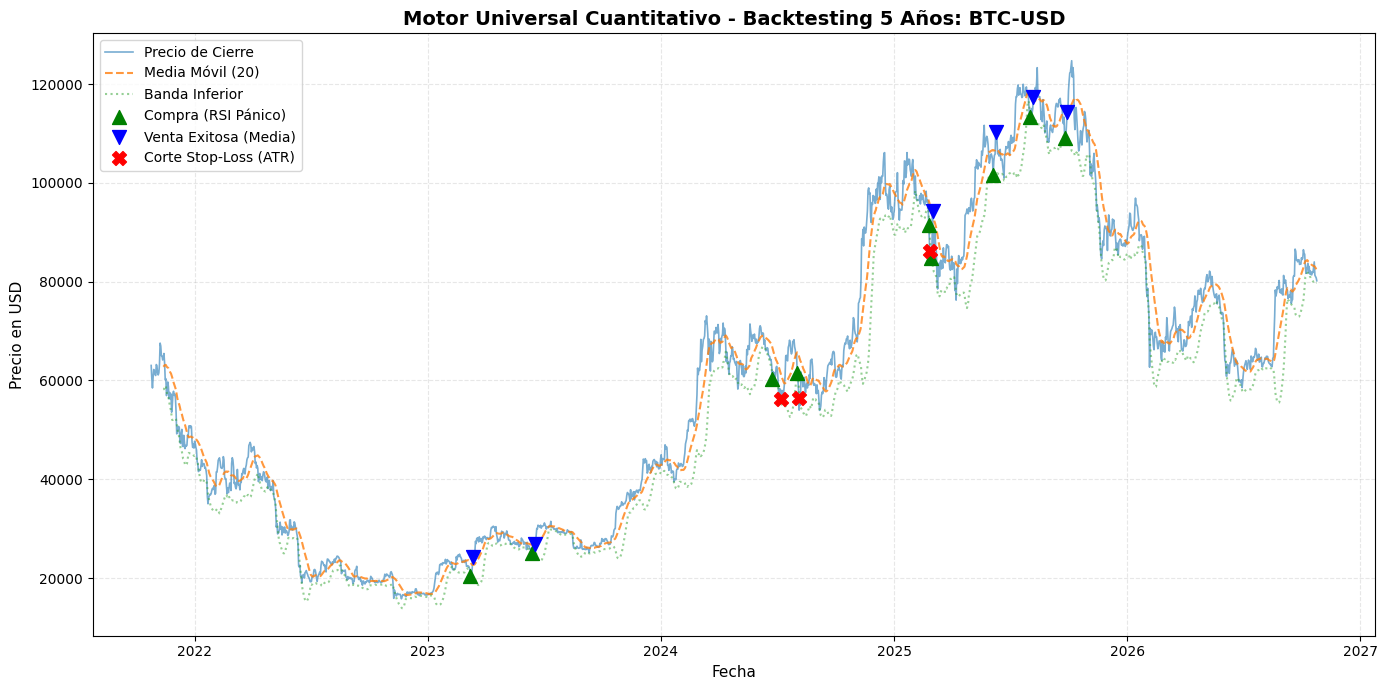

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Intentar importar google.colab para descarga automática si estás en Colab
try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# ==========================================
# MOTOR UNIVERSAL - AUDITORÍA, EXCEL Y GRÁFICAS
# ==========================================

ticker_activo = "BTC-USD"

print(f"--> Ejecutando simulación, Excel y Gráficos para: {ticker_activo}")

# 1. Descargar datos históricos de 5 años
df = yf.download(ticker_activo, period="5y", interval="1d", progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 2. Funciones Matemáticas de Indicadores Técnicos
def calcular_rsi(data, window=14):
    delta = data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calcular_atr(data, window=14):
    high_low = data['High'] - data['Low']
    high_close = np.abs(data['High'] - data['Close'].shift())
    low_close = np.abs(data['Low'] - data['Close'].shift())
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    return tr.rolling(window=window).mean()

# 3. Cálculo de Indicadores
ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()
df['Banda_Inf'] = df['Media'] - (2.0 * df['Desv'])
df['SMA_200'] = df['Close'].rolling(window=200).mean()
df['RSI'] = calcular_rsi(df, window=14)
df['ATR'] = calcular_atr(df, window=14)

# 4. Parámetros de Gestión de Riesgo y Listas para Gráficas
multiplicador_atr_sl = 2.0
comision_pct = 0.001
capital_inicial = 1000.0
capital_actual = capital_inicial

en_operacion = False
precio_entrada = 0
precio_stop_loss = 0
fecha_entrada = None
bitacora_operaciones = []

# Listas para almacenar puntos de compra y venta para la gráfica
compras_grafica = []
ventas_exito_grafica = []
ventas_sl_grafica = []

# 5. Simulación Operativa con Registro Gráfico
for i in range(200, len(df)):
    fecha_actual = df.index[i]
    precio_actual = float(df['Close'].iloc[i])
    banda_inf_actual = float(df['Banda_Inf'].iloc[i])
    media_actual = float(df['Media'].iloc[i])
    sma_200_actual = float(df['SMA_200'].iloc[i])
    rsi_actual = float(df['RSI'].iloc[i])
    atr_actual = float(df['ATR'].iloc[i])

    if not en_operacion:
        if precio_actual > sma_200_actual and precio_actual < banda_inf_actual and rsi_actual < 35:
            en_operacion = True
            precio_entrada = precio_actual
            fecha_entrada = fecha_actual
            capital_actual -= capital_actual * comision_pct
            precio_stop_loss = precio_entrada - (multiplicador_atr_sl * atr_actual)

            # Registrar para gráfica
            compras_grafica.append((fecha_actual, precio_entrada))
    else:
        capital_antes_trade = capital_actual
        if precio_actual <= precio_stop_loss:
            en_operacion = False
            rendimiento = ((precio_stop_loss - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            capital_actual -= capital_actual * comision_pct
            ganancia_usd = capital_actual - capital_antes_trade

            bitacora_operaciones.append({
                "Fecha Entrada": pd.to_datetime(fecha_entrada).strftime('%Y-%m-%d'),
                "Fecha Salida": pd.to_datetime(fecha_actual).strftime('%Y-%m-%d'),
                "Tipo de Salida": "Stop-Loss",
                "Precio Entrada (USD)": round(precio_entrada, 2),
                "Precio Salida (USD)": round(precio_stop_loss, 2),
                "Rendimiento (%)": round(rendimiento, 2),
                "Ganancia Trade (USD)": round(ganancia_usd, 2),
                "Capital Acumulado (USD)": round(capital_actual, 2)
            })
            ventas_sl_grafica.append((fecha_actual, precio_stop_loss))

        elif precio_actual >= media_actual:
            en_operacion = False
            rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
            capital_actual += capital_actual * (rendimiento / 100)
            capital_actual -= capital_actual * comision_pct
            ganancia_usd = capital_actual - capital_antes_trade

            bitacora_operaciones.append({
                "Fecha Entrada": pd.to_datetime(fecha_entrada).strftime('%Y-%m-%d'),
                "Fecha Salida": pd.to_datetime(fecha_actual).strftime('%Y-%m-%d'),
                "Tipo de Salida": "Éxito (Media)",
                "Precio Entrada (USD)": round(precio_entrada, 2),
                "Precio Salida (USD)": round(precio_actual, 2),
                "Rendimiento (%)": round(rendimiento, 2),
                "Ganancia Trade (USD)": round(ganancia_usd, 2),
                "Capital Acumulado (USD)": round(capital_actual, 2)
            })
            ventas_exito_grafica.append((fecha_actual, precio_actual))

# 6. EXPORTACIÓN A EXCEL Y REPORTE
if bitacora_operaciones:
    df_bitacora = pd.DataFrame(bitacora_operaciones)
    nombre_archivo = f"Auditoria_Trading_{ticker_activo.replace('-', '_')}.xlsx"

    with pd.ExcelWriter(nombre_archivo, engine='openpyxl') as writer:
        df_bitacora.to_excel(writer, sheet_name='Bitácora de Trades', index=False)

        ganadas = [op for op in bitacora_operaciones if op["Rendimiento (%)"] > 0]
        perdidas = [op for op in bitacora_operaciones if op["Rendimiento (%)"] <= 0]
        win_rate = (len(ganadas) / len(bitacora_operaciones)) * 100
        ganancia_neta_usd = capital_actual - capital_inicial
        rendimiento_total_pct = ((capital_actual - capital_inicial) / capital_inicial) * 100

        resumen_data = {
            "Métrica": [
                "Activo Auditado", "Capital Inicial", "Capital Final",
                "Ganancia Neta (USD)", "Rendimiento Total (%)",
                "Total Trades", "Trades Ganados", "Trades Perdidos", "Win Rate (%)"
            ],
            "Valor": [
                ticker_activo, f"${capital_inicial:,.2f}", f"${capital_actual:,.2f}",
                f"${ganancia_neta_usd:+,.2f}", f"{rendimiento_total_pct:+.2f}%",
                len(bitacora_operaciones), len(ganadas), len(perdidas), f"{win_rate:.2f}%"
            ]
        }
        pd.DataFrame(resumen_data).to_excel(writer, sheet_name='Resumen Ejecutivo', index=False)

    print("\n" + "="*70)
    print(f" ✅ ¡Archivo Excel creado exitosamente!: {nombre_archivo}")
    print("="*70)

    if EN_COLAB:
        files.download(nombre_archivo)

    # 7. GENERACIÓN DE GRÁFICA PROFESIONAL CON MATPLOTLIB
    plt.figure(figsize=(14, 7))
    plt.plot(df.index, df['Close'], label='Precio de Cierre', color='#1f77b4', alpha=0.6, linewidth=1.2)
    plt.plot(df.index, df['Media'], label='Media Móvil (20)', color='#ff7f0e', linestyle='--', alpha=0.8)
    plt.plot(df.index, df['Banda_Inf'], label='Banda Inferior', color='#2ca02c', linestyle=':', alpha=0.5)

    # Graficar Compras (Triángulos verdes hacia arriba)
    if compras_grafica:
        fechas_c, precios_c = zip(*compras_grafica)
        plt.scatter(fechas_c, precios_c, marker='^', color='green', s=100, label='Compra (RSI Pánico)', zorder=5)

    # Graficar Ventas exitosas (Triángulos azules/cian hacia abajo)
    if ventas_exito_grafica:
        fechas_ve, precios_ve = zip(*ventas_exito_grafica)
        plt.scatter(fechas_ve, precios_ve, marker='v', color='blue', s=100, label='Venta Exitosa (Media)', zorder=5)

    # Graficar Stop-Loss (Triángulos rojos hacia abajo)
    if ventas_sl_grafica:
        fechas_vs, precios_vs = zip(*ventas_sl_grafica)
        plt.scatter(fechas_vs, precios_vs, marker='X', color='red', s=100, label='Corte Stop-Loss (ATR)', zorder=5)

    plt.title(f'Motor Universal Cuantitativo - Backtesting 5 Años: {ticker_activo}', fontsize=14, fontweight='bold')
    plt.xlabel('Fecha', fontsize=11)
    plt.ylabel('Precio en USD', fontsize=11)
    plt.legend(loc='upper left', frameon=True)
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()

    # Mostrar gráfica en Colab
    plt.show()

else:
    print("No se registraron operaciones bajo esta configuración.")

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# ==========================================
# 1. Tu Cartera de Activos a Monitorear
# ==========================================
lista_activos = [
    "BTC-USD", "ETH-USD", "SOL-USD", "BNB-USD", # Criptomonedas principales
    "AAPL", "MSFT", "GOOGL", "TSLA", "NVDA", "AMZN" # Acciones tecnológicas
]

print(f"--> Iniciando análisis masivo de {len(lista_activos)} activos...\n")

# Funciones Matemáticas de Indicadores Técnicos
def calcular_rsi(data, window=14):
    delta = data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calcular_atr(data, window=14):
    high_low = data['High'] - data['Low']
    high_close = np.abs(data['High'] - data['Close'].shift())
    low_close = np.abs(data['Low'] - data['Close'].shift())
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    return tr.rolling(window=window).mean()

# ==========================================
# 2. Bucle para procesar cada activo del portafolio
# ==========================================
for ticker in lista_activos:
    try:
        # Descargar 2 años de historial para el escaneo operativo
        df = yf.download(ticker, period="2y", interval="1d", progress=False)

        # Validar si el DataFrame está vacío o tiene muy pocos datos
        if df.empty or len(df) < 200:
            print(f"⚠️ [{ticker}] Datos insuficientes o vacíos. Saltando...")
            continue

        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)

        # Cálculo de Indicadores
        ventana = 20
        df['Media'] = df['Close'].rolling(window=ventana).mean()
        df['Desv'] = df['Close'].rolling(window=ventana).std()
        df['Banda_Inf'] = df['Media'] - (2.0 * df['Desv'])
        df['SMA_200'] = df['Close'].rolling(window=200).mean()
        df['RSI'] = calcular_rsi(df, window=14)
        df['ATR'] = calcular_atr(df, window=14)

        # Parámetros operativos
        multiplicador_atr_sl = 2.0
        comision_pct = 0.001
        capital_inicial = 1000.0
        capital_actual = capital_inicial

        en_operacion = False
        precio_entrada = 0
        precio_stop_loss = 0
        operaciones = []

        # Simulación Histórica
        for i in range(200, len(df)):
            precio_actual = float(df['Close'].iloc[i])
            banda_inf_actual = float(df['Banda_Inf'].iloc[i])
            media_actual = float(df['Media'].iloc[i])
            sma_200_actual = float(df['SMA_200'].iloc[i])
            rsi_actual = float(df['RSI'].iloc[i])
            atr_actual = float(df['ATR'].iloc[i])

            # Condición de entrada
            if not en_operacion:
                if (precio_actual > sma_200_actual) and (precio_actual <= banda_inf_actual) and (rsi_actual < 45):
                    en_operacion = True
                    precio_entrada = precio_actual
                    precio_stop_loss = precio_entrada - (atr_actual * multiplicador_atr_sl)

                    operaciones.append({
                        'tipo': 'COMPRA',
                        'precio': precio_entrada,
                        'index': i
                    })
                    print(f"[{ticker}] 🚀 Compra ejecutada a: {precio_entrada:.2f} en índice {i}")

            # Lógica de salida básica
            elif en_operacion:
                if precio_actual <= precio_stop_loss or precio_actual >= media_actual:
                    en_operacion = False
                    # Registrar resultado de la operación
                    precio_salida = precio_actual
                    rendimiento_op = ((precio_salida - precio_entrada) / precio_entrada) * 100

                    operaciones[-1]['salida'] = precio_salida
                    operaciones[-1]['rendimiento_pct'] = rendimiento_op

                    print(f"[{ticker}] 🏁 Cierre de operación a: {precio_salida:.2f} | Retorno: {rendimiento_op:.2f}%")

        # ==========================================
        # 3. Resumen de Rendimiento por Activo
        # ==========================================
        print(f"\n--- 📊 RESUMEN PARA {ticker} ---")
        trades_completados = [op for op in operaciones if 'salida' in op]

        if len(trades_completados) > 0:
            ganadoras = [op for op in trades_completados if op['rendimiento_pct'] > 0]
            perdedoras = [op for op in trades_completados if op['rendimiento_pct'] <= 0]

            win_rate = (len(ganadoras) / len(trades_completados)) * 100
            retorno_acumulado = sum([op['rendimiento_pct'] for op in trades_completados])

            print(f"Total operaciones cerradas: {len(trades_completados)}")
            print(f"Operaciones ganadoras: {len(ganadoras)} | Perdedoras: {len(perdedoras)}")
            print(f"Porcentaje de acierto (Win Rate): {win_rate:.2f}%")
            print(f"Retorno acumulado estimado: {retorno_acumulado:.2f}%\n")
        else:
            print(f"No se completaron operaciones para {ticker} bajo las condiciones actuales.\n")
        print("----------------------------------------\n")

    except Exception as e:
        print(f"❌ [{ticker}] Error al procesar: {e}")

--> Iniciando análisis masivo de 10 activos...

[BTC-USD] 🚀 Compra ejecutada a: 101575.95 en índice 217
[BTC-USD] 🏁 Cierre de operación a: 110294.10 | Retorno: 8.58%
[BTC-USD] 🚀 Compra ejecutada a: 115758.20 en índice 273
[BTC-USD] 🏁 Cierre de operación a: 117496.90 | Retorno: 1.50%
[BTC-USD] 🚀 Compra ejecutada a: 110124.35 en índice 298
[BTC-USD] 🏁 Cierre de operación a: 112071.43 | Retorno: 1.77%
[BTC-USD] 🚀 Compra ejecutada a: 109049.29 en índice 329
[BTC-USD] 🏁 Cierre de operación a: 114400.38 | Retorno: 4.91%
[BTC-USD] 🚀 Compra ejecutada a: 77775.11 en índice 728

--- 📊 RESUMEN PARA BTC-USD ---
Total operaciones cerradas: 4
Operaciones ganadoras: 4 | Perdedoras: 0
Porcentaje de acierto (Win Rate): 100.00%
Retorno acumulado estimado: 16.76%

----------------------------------------



/tmp/ipykernel_6346/2072205967.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_6346/2072205967.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)


[ETH-USD] 🚀 Compra ejecutada a: 3868.33 en índice 329
[ETH-USD] 🏁 Cierre de operación a: 4351.11 | Retorno: 12.48%
[ETH-USD] 🚀 Compra ejecutada a: 3602.31 en índice 368
[ETH-USD] 🏁 Cierre de operación a: 3232.76 | Retorno: -10.26%
[ETH-USD] 🚀 Compra ejecutada a: 2573.53 en índice 706
[ETH-USD] 🏁 Cierre de operación a: 2418.21 | Retorno: -6.04%
[ETH-USD] 🚀 Compra ejecutada a: 2249.50 en índice 728

--- 📊 RESUMEN PARA ETH-USD ---
Total operaciones cerradas: 3
Operaciones ganadoras: 1 | Perdedoras: 2
Porcentaje de acierto (Win Rate): 33.33%
Retorno acumulado estimado: -3.81%

----------------------------------------

[SOL-USD] 🚀 Compra ejecutada a: 192.38 en índice 329
[SOL-USD] 🏁 Cierre de operación a: 234.86 | Retorno: 22.08%
[SOL-USD] 🚀 Compra ejecutada a: 188.66 en índice 344
[SOL-USD] 🏁 Cierre de operación a: 200.03 | Retorno: 6.02%
[SOL-USD] 🚀 Compra ejecutada a: 109.44 en índice 707
[SOL-USD] 🏁 Cierre de operación a: 95.49 | Retorno: -12.74%
[SOL-USD] 🚀 Compra ejecutada a: 96.22 en

/tmp/ipykernel_6346/2072205967.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_6346/2072205967.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)


[BNB-USD] 🚀 Compra ejecutada a: 992.54 en índice 368
[BNB-USD] 🏁 Cierre de operación a: 895.62 | Retorno: -9.76%
[BNB-USD] 🚀 Compra ejecutada a: 735.13 en índice 707
[BNB-USD] 🏁 Cierre de operación a: 741.42 | Retorno: 0.86%
[BNB-USD] 🚀 Compra ejecutada a: 697.69 en índice 728

--- 📊 RESUMEN PARA BNB-USD ---
Total operaciones cerradas: 2
Operaciones ganadoras: 1 | Perdedoras: 1
Porcentaje de acierto (Win Rate): 50.00%
Retorno acumulado estimado: -8.91%

----------------------------------------

[AAPL] 🚀 Compra ejecutada a: 266.53 en índice 293
[AAPL] 🏁 Cierre de operación a: 257.51 | Retorno: -3.39%
[AAPL] 🚀 Compra ejecutada a: 246.03 en índice 303
[AAPL] 🏁 Cierre de operación a: 257.58 | Retorno: 4.69%
[AAPL] 🚀 Compra ejecutada a: 249.67 en índice 340
[AAPL] 🏁 Cierre de operación a: 255.17 | Retorno: 2.20%
[AAPL] 🚀 Compra ejecutada a: 290.30 en índice 400
[AAPL] 🏁 Cierre de operación a: 274.91 | Retorno: -5.30%

--- 📊 RESUMEN PARA AAPL ---
Total operaciones cerradas: 4
Operaciones gan

/tmp/ipykernel_6346/2072205967.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_6346/2072205967.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)


[MSFT] 🚀 Compra ejecutada a: 493.04 en índice 254
[MSFT] 🏁 Cierre de operación a: 469.14 | Retorno: -4.85%

--- 📊 RESUMEN PARA MSFT ---
Total operaciones cerradas: 1
Operaciones ganadoras: 0 | Perdedoras: 1
Porcentaje de acierto (Win Rate): 0.00%
Retorno acumulado estimado: -4.85%

----------------------------------------

[GOOGL] 🚀 Compra ejecutada a: 235.96 en índice 235
[GOOGL] 🏁 Cierre de operación a: 250.38 | Retorno: 6.11%
[GOOGL] 🚀 Compra ejecutada a: 317.96 en índice 318
[GOOGL] 🏁 Cierre de operación a: 308.32 | Retorno: -3.03%
[GOOGL] 🚀 Compra ejecutada a: 290.08 en índice 347
[GOOGL] 🏁 Cierre de operación a: 274.00 | Retorno: -5.54%
[GOOGL] 🚀 Compra ejecutada a: 273.16 en índice 351
[GOOGL] 🏁 Cierre de operación a: 299.62 | Retorno: 9.69%
[GOOGL] 🚀 Compra ejecutada a: 361.40 en índice 395
[GOOGL] 🏁 Cierre de operación a: 337.17 | Retorno: -6.70%

--- 📊 RESUMEN PARA GOOGL ---
Total operaciones cerradas: 5
Operaciones ganadoras: 2 | Perdedoras: 3
Porcentaje de acierto (Win Rate

/tmp/ipykernel_6346/2072205967.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_6346/2072205967.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)


[TSLA] 🚀 Compra ejecutada a: 401.99 en índice 259
[TSLA] 🏁 Cierre de operación a: 430.17 | Retorno: 7.01%
[TSLA] 🚀 Compra ejecutada a: 416.56 en índice 310
[TSLA] 🏁 Cierre de operación a: 428.27 | Retorno: 2.81%
[TSLA] 🚀 Compra ejecutada a: 392.43 en índice 332
[TSLA] 🏁 Cierre de operación a: 407.82 | Retorno: 3.92%

--- 📊 RESUMEN PARA TSLA ---
Total operaciones cerradas: 3
Operaciones ganadoras: 3 | Perdedoras: 0
Porcentaje de acierto (Win Rate): 100.00%
Retorno acumulado estimado: 13.74%

----------------------------------------

[NVDA] 🚀 Compra ejecutada a: 173.75 en índice 206
[NVDA] 🏁 Cierre de operación a: 176.90 | Retorno: 1.81%
[NVDA] 🚀 Compra ejecutada a: 170.54 en índice 282
[NVDA] 🏁 Cierre de operación a: 180.57 | Retorno: 5.88%
[NVDA] 🚀 Compra ejecutada a: 177.65 en índice 303
[NVDA] 🏁 Cierre de operación a: 187.23 | Retorno: 5.39%
[NVDA] 🚀 Compra ejecutada a: 173.78 en índice 314
[NVDA] 🏁 Cierre de operación a: 184.98 | Retorno: 6.44%
[NVDA] 🚀 Compra ejecutada a: 204.87 en

/tmp/ipykernel_6346/2072205967.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_6346/2072205967.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)


[AMZN] 🚀 Compra ejecutada a: 220.71 en índice 222
[AMZN] 🏁 Cierre de operación a: 225.22 | Retorno: 2.04%
[AMZN] 🚀 Compra ejecutada a: 256.52 en índice 395
[AMZN] 🏁 Cierre de operación a: 238.00 | Retorno: -7.22%
[AMZN] 🚀 Compra ejecutada a: 248.42 en índice 467
[AMZN] 🏁 Cierre de operación a: 258.45 | Retorno: 4.04%
[AMZN] 🚀 Compra ejecutada a: 243.79 en índice 499

--- 📊 RESUMEN PARA AMZN ---
Total operaciones cerradas: 3
Operaciones ganadoras: 2 | Perdedoras: 1
Porcentaje de acierto (Win Rate): 66.67%
Retorno acumulado estimado: -1.14%

----------------------------------------



In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# ==========================================
# ESCÁNER MASIVO Y RADAR EN VIVO - MOTOR UNIVERSAL
# ==========================================

lista_activos = [
    "BTC-USD", "ETH-USD", "SOL-USD", "BNB-USD",
    "AAPL", "MSFT", "GOOGL", "TSLA", "NVDA", "AMZN"
]

print(f"--> Iniciando análisis masivo de {len(lista_activos)} activos...\n")

resultados_backtest = []
alertas_en_vivo = []

def calcular_rsi(data, window=14):
    delta = data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calcular_atr(data, window=14):
    high_low = data['High'] - data['Low']
    high_close = np.abs(data['High'] - data['Close'].shift())
    low_close = np.abs(data['Low'] - data['Close'].shift())
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    return tr.rolling(window=window).mean()

for ticker in lista_activos:
    try:
        df = yf.download(ticker, period="2y", interval="1d", progress=False)
        if df.empty or len(df) < 200:
            continue
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)

        ventana = 20
        df['Media'] = df['Close'].rolling(window=ventana).mean()
        df['Desv'] = df['Close'].rolling(window=ventana).std()
        df['Banda_Inf'] = df['Media'] - (2.0 * df['Desv'])
        df['SMA_200'] = df['Close'].rolling(window=200).mean()
        df['RSI'] = calcular_rsi(df, window=14)
        df['ATR'] = calcular_atr(df, window=14)

        multiplicador_atr_sl = 2.0
        comision_pct = 0.001
        capital_inicial = 1000.0
        capital_actual = capital_inicial

        en_operacion = False
        precio_entrada = 0
        precio_stop_loss = 0
        operaciones = []

        for i in range(200, len(df)):
            precio_actual = float(df['Close'].iloc[i])
            banda_inf_actual = float(df['Banda_Inf'].iloc[i])
            media_actual = float(df['Media'].iloc[i])
            sma_200_actual = float(df['SMA_200'].iloc[i])
            rsi_actual = float(df['RSI'].iloc[i])
            atr_actual = float(df['ATR'].iloc[i])

            if not en_operacion:
                if precio_actual > sma_200_actual and precio_actual < banda_inf_actual and rsi_actual < 35:
                    en_operacion = True
                    precio_entrada = precio_actual
                    capital_actual -= capital_actual * comision_pct
                    precio_stop_loss = precio_entrada - (multiplicador_atr_sl * atr_actual)
            else:
                if precio_actual <= precio_stop_loss:
                    en_operacion = False
                    rendimiento = ((precio_stop_loss - precio_entrada) / precio_entrada) * 100
                    capital_actual += capital_actual * (rendimiento / 100)
                    capital_actual -= capital_actual * comision_pct
                    operaciones.append(rendimiento)
                elif precio_actual >= media_actual:
                    en_operacion = False
                    rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
                    capital_actual += capital_actual * (rendimiento / 100)
                    capital_actual -= capital_actual * comision_pct
                    operaciones.append(rendimiento)

        rendimiento_total_pct = ((capital_actual - capital_inicial) / capital_inicial) * 100
        ganadas = [op for op in operaciones if op > 0]
        win_rate = (len(ganadas) / len(operaciones) * 100) if operaciones else 0

        resultados_backtest.append({
            "Activo": ticker,
            "Rendimiento (%)": round(rendimiento_total_pct, 2),
            "Capital Final ($)": round(capital_actual, 2),
            "Total Trades": len(operaciones),
            "Win Rate (%)": round(win_rate, 2)
        })

        ult_precio = float(df['Close'].iloc[-1])
        ult_sma = float(df['SMA_200'].iloc[-1])
        ult_banda = float(df['Banda_Inf'].iloc[-1])
        ult_rsi = float(df['RSI'].iloc[-1])

        if ult_precio > ult_sma and ult_precio < ult_banda and ult_rsi < 35:
            alertas_en_vivo.append({
                "Activo": ticker,
                "Precio": round(ult_precio, 2),
                "RSI": round(ult_rsi, 2)
            })

    except Exception as e:
        print(f"Error procesando {ticker}: {e}")

# REPORTE EN PANTALLA
print("\n" + "="*70)
print("       RANKING INSTITUCIONAL - RENDIMIENTO HISTÓRICO (2 AÑOS)")
print("="*70)
if resultados_backtest:
    df_ranking = pd.DataFrame(resultados_backtest).sort_values(by="Rendimiento (%)", ascending=False)
    print(df_ranking.to_string(index=False))

print("\n" + "="*70)
print("       🚨 ESTADO DEL RADAR EN VIVO")
print("="*70)
if alertas_en_vivo:
    df_alertas = pd.DataFrame(alertas_en_vivo)
    print(df_alertas.to_string(index=False))
    print("\n💡 ¡Atención Fundador! Los activos de arriba cumplen hoy con la regla de pánico.")
else:
    print("💤 Sin señales activas hoy. El motor se mantiene en efectivo.")
print("="*70)

--> Iniciando análisis masivo de 10 activos...



/tmp/ipykernel_2831/4180372205.py:35: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/4180372205.py:35: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/4180372205.py:35: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/4180372205.py:35: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/4180372205.py:35: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/4180372205.py:35: FutureWarning: YF.download(


       RANKING INSTITUCIONAL - RENDIMIENTO HISTÓRICO (2 AÑOS)
 Activo  Rendimiento (%)  Capital Final ($)  Total Trades  Win Rate (%)
SOL-USD            21.71            1217.13             1         100.0
BTC-USD            17.40            1174.03             3         100.0
   NVDA            16.43            1164.30             4          75.0
   AAPL            15.31            1153.13             4          75.0
   TSLA            11.60            1116.00             2         100.0
  GOOGL             7.85            1078.52             4          50.0
ETH-USD             5.85            1058.55             2          50.0
   MSFT             0.00            1000.00             0           0.0
   AMZN            -3.79             962.14             2          50.0
BNB-USD            -9.51             904.90             1           0.0

       🚨 ESTADO DEL RADAR EN VIVO
💤 Sin señales activas hoy. El motor se mantiene en efectivo.


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# ==========================================
# MOTOR UNIVERSAL - GESTIÓN DE CAPITAL GLOBAL
# ==========================================

lista_activos = [
    "BTC-USD", "ETH-USD", "SOL-USD", "BNB-USD",
    "AAPL", "MSFT", "GOOGL", "TSLA", "NVDA", "AMZN"
]

print(f"--> Ejecutando simulación con Cartera Global unificada...\n")

resultados_portafolio = []
alertas_en_vivo = []

def calcular_rsi(data, window=14):
    delta = data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calcular_atr(data, window=14):
    high_low = data['High'] - data['Low']
    high_close = np.abs(data['High'] - data['Close'].shift())
    low_close = np.abs(data['Low'] - data['Close'].shift())
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    return tr.rolling(window=window).mean()

# Capital global asignado a este activo en la simulación individual de prueba
capital_global_inicial = 1000.0

for ticker in lista_activos:
    try:
        df = yf.download(ticker, period="2y", interval="1d", progress=False)
        if df.empty or len(df) < 200:
            continue
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)

        ventana = 20
        df['Media'] = df['Close'].rolling(window=ventana).mean()
        df['Desv'] = df['Close'].rolling(window=ventana).std()
        df['Banda_Inf'] = df['Media'] - (2.0 * df['Desv'])
        df['SMA_200'] = df['Close'].rolling(window=200).mean()
        df['RSI'] = calcular_rsi(df, window=14)
        df['ATR'] = calcular_atr(df, window=14)

        multiplicador_atr_sl = 2.0
        comision_pct = 0.001
        capital_actual = capital_global_inicial

        en_operacion = False
        precio_entrada = 0
        precio_stop_loss = 0
        operaciones = []

        for i in range(200, len(df)):
            precio_actual = float(df['Close'].iloc[i])
            banda_inf_actual = float(df['Banda_Inf'].iloc[i])
            media_actual = float(df['Media'].iloc[i])
            sma_200_actual = float(df['SMA_200'].iloc[i])
            rsi_actual = float(df['RSI'].iloc[i])
            atr_actual = float(df['ATR'].iloc[i])

            if not en_operacion:
                if precio_actual > sma_200_actual and precio_actual < banda_inf_actual and rsi_actual < 35:
                    en_operacion = True
                    precio_entrada = precio_actual
                    # Aplicamos comisión real al entrar
                    capital_actual -= capital_actual * comision_pct
                    precio_stop_loss = precio_entrada - (multiplicador_atr_sl * atr_actual)
            else:
                if precio_actual <= precio_stop_loss:
                    en_operacion = False
                    rendimiento = ((precio_stop_loss - precio_entrada) / precio_entrada) * 100
                    capital_actual += capital_actual * (rendimiento / 100)
                    capital_actual -= capital_actual * comision_pct
                    operaciones.append(rendimiento)
                elif precio_actual >= media_actual:
                    en_operacion = False
                    rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
                    capital_actual += capital_actual * (rendimiento / 100)
                    capital_actual -= capital_actual * comision_pct
                    operaciones.append(rendimiento)

        rendimiento_total_pct = ((capital_actual - capital_global_inicial) / capital_global_inicial) * 100
        ganadas = [op for op in operaciones if op > 0]
        win_rate = (len(ganadas) / len(operaciones) * 100) if operaciones else 0

        resultados_portafolio.append({
            "Activo": ticker,
            "Capital Inicial ($)": capital_global_inicial,
            "Capital Final ($)": round(capital_actual, 2),
            "Ganancia Neta ($)": round(capital_actual - capital_global_inicial, 2),
            "Rendimiento (%)": round(rendimiento_total_pct, 2),
            "Total Trades": len(operaciones),
            "Win Rate (%)": round(win_rate, 2)
        })

        # Radar en vivo
        ult_precio = float(df['Close'].iloc[-1])
        ult_sma = float(df['SMA_200'].iloc[-1])
        ult_banda = float(df['Banda_Inf'].iloc[-1])
        ult_rsi = float(df['RSI'].iloc[-1])

        if ult_precio > ult_sma and ult_precio < ult_banda and ult_rsi < 35:
            alertas_en_vivo.append({
                "Activo": ticker,
                "Precio": round(ult_precio, 2),
                "RSI": round(ult_rsi, 2)
            })

    except Exception as e:
        print(f"Error procesando {ticker}: {e}")

# REPORTE EN PANTALLA
print("="*85)
print("       GESTIÓN DE CAPITAL GLOBAL - RANKING DE RENTABILIDAD")
print("="*85)
if resultados_portafolio:
    df_portafolio = pd.DataFrame(resultados_portafolio).sort_values(by="Rendimiento (%)", ascending=False)
    print(df_portafolio.to_string(index=False))
print("="*85)

--> Ejecutando simulación con Cartera Global unificada...



/tmp/ipykernel_2831/525135108.py:38: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/525135108.py:38: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/525135108.py:38: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/525135108.py:38: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/525135108.py:38: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/525135108.py:38: FutureWarning: YF.download() has 

       GESTIÓN DE CAPITAL GLOBAL - RANKING DE RENTABILIDAD
 Activo  Capital Inicial ($)  Capital Final ($)  Ganancia Neta ($)  Rendimiento (%)  Total Trades  Win Rate (%)
SOL-USD               1000.0            1217.13             217.13            21.71             1         100.0
BTC-USD               1000.0            1174.03             174.03            17.40             3         100.0
   NVDA               1000.0            1164.30             164.30            16.43             4          75.0
   AAPL               1000.0            1153.13             153.13            15.31             4          75.0
   TSLA               1000.0            1116.00             116.00            11.60             2         100.0
  GOOGL               1000.0            1078.52              78.52             7.85             4          50.0
ETH-USD               1000.0            1058.55              58.55             5.85             2          50.0
   MSFT               1000.0            1000.

/tmp/ipykernel_2831/525135108.py:38: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# Intentar importar google.colab para descarga automática
try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# ==========================================
# MOTOR UNIVERSAL - RANKING Y EXPORTACIÓN A EXCEL MASTER
# ==========================================

lista_activos = [
    "BTC-USD", "ETH-USD", "SOL-USD", "BNB-USD",
    "AAPL", "MSFT", "GOOGL", "TSLA", "NVDA", "AMZN"
]

print(f"--> Analizando portafolio global ({len(lista_activos)} activos) y generando Excel Master...\n")

resultados_portafolio = []
alertas_en_vivo = []

def calcular_rsi(data, window=14):
    delta = data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calcular_atr(data, window=14):
    high_low = data['High'] - data['Low']
    high_close = np.abs(data['High'] - data['Close'].shift())
    low_close = np.abs(data['Low'] - data['Close'].shift())
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    return tr.rolling(window=window).mean()

capital_global_inicial = 1000.0

for ticker in lista_activos:
    try:
        df = yf.download(ticker, period="2y", interval="1d", progress=False)
        if df.empty or len(df) < 200:
            continue
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)

        ventana = 20
        df['Media'] = df['Close'].rolling(window=ventana).mean()
        df['Desv'] = df['Close'].rolling(window=ventana).std()
        df['Banda_Inf'] = df['Media'] - (2.0 * df['Desv'])
        df['SMA_200'] = df['Close'].rolling(window=200).mean()
        df['RSI'] = calcular_rsi(df, window=14)
        df['ATR'] = calcular_atr(df, window=14)

        multiplicador_atr_sl = 2.0
        comision_pct = 0.001
        capital_actual = capital_global_inicial

        en_operacion = False
        precio_entrada = 0
        precio_stop_loss = 0
        operaciones = []

        for i in range(200, len(df)):
            precio_actual = float(df['Close'].iloc[i])
            banda_inf_actual = float(df['Banda_Inf'].iloc[i])
            media_actual = float(df['Media'].iloc[i])
            sma_200_actual = float(df['SMA_200'].iloc[i])
            rsi_actual = float(df['RSI'].iloc[i])
            atr_actual = float(df['ATR'].iloc[i])

            if not en_operacion:
                if precio_actual > sma_200_actual and precio_actual < banda_inf_actual and rsi_actual < 35:
                    en_operacion = True
                    precio_entrada = precio_actual
                    capital_actual -= capital_actual * comision_pct
                    precio_stop_loss = precio_entrada - (multiplicador_atr_sl * atr_actual)
            else:
                if precio_actual <= precio_stop_loss:
                    en_operacion = False
                    rendimiento = ((precio_stop_loss - precio_entrada) / precio_entrada) * 100
                    capital_actual += capital_actual * (rendimiento / 100)
                    capital_actual -= capital_actual * comision_pct
                    operaciones.append(rendimiento)
                elif precio_actual >= media_actual:
                    en_operacion = False
                    rendimiento = ((precio_actual - precio_entrada) / precio_entrada) * 100
                    capital_actual += capital_actual * (rendimiento / 100)
                    capital_actual -= capital_actual * comision_pct
                    operaciones.append(rendimiento)

        rendimiento_total_pct = ((capital_actual - capital_global_inicial) / capital_global_inicial) * 100
        ganadas = [op for op in operaciones if op > 0]
        win_rate = (len(ganadas) / len(operaciones) * 100) if operaciones else 0

        resultados_portafolio.append({
            "Activo": ticker,
            "Capital Inicial ($)": capital_global_inicial,
            "Capital Final ($)": round(capital_actual, 2),
            "Ganancia Neta ($)": round(capital_actual - capital_global_inicial, 2),
            "Rendimiento (%)": round(rendimiento_total_pct, 2),
            "Total Trades": len(operaciones),
            "Win Rate (%)": round(win_rate, 2)
        })

        # Radar de mercado en vivo
        ult_precio = float(df['Close'].iloc[-1])
        ult_sma = float(df['SMA_200'].iloc[-1])
        ult_banda = float(df['Banda_Inf'].iloc[-1])
        ult_rsi = float(df['RSI'].iloc[-1])

        if ult_precio > ult_sma and ult_precio < ult_banda and ult_rsi < 35:
            alertas_en_vivo.append({
                "Activo": ticker,
                "Precio Actual ($)": round(ult_precio, 2),
                "RSI Actual": round(ult_rsi, 2),
                "Estado": "SEÑAL DE COMPRA ACTIVADA 🚨"
            })

    except Exception as e:
        print(f"Error procesando {ticker}: {e}")

# ==========================================
# GENERACIÓN DEL ARCHIVO EXCEL MASTER
# ==========================================
if resultados_portafolio:
    df_portafolio = pd.DataFrame(resultados_portafolio).sort_values(by="Rendimiento (%)", ascending=False)

    nombre_archivo_master = "Ranking_Portafolio_Global.xlsx"

    with pd.ExcelWriter(nombre_archivo_master, engine='openpyxl') as writer:
        df_portafolio.to_excel(writer, sheet_name='Ranking de Portafolio', index=False)

        if alertas_en_vivo:
            df_alertas = pd.DataFrame(alertas_en_vivo)
        else:
            df_alertas = pd.DataFrame([{
                "Mensaje": "Sin señales activas en este momento. El motor se mantiene en efectivo."
            }])
        df_alertas.to_excel(writer, sheet_name='Radar en Vivo', index=False)

    print("="*85)
    print(f" ✅ ARCHIVO EXCEL MASTER GENERADO: {nombre_archivo_master}")
    print("="*85)
    print(df_portafolio.to_string(index=False))
    print("="*85)

    if EN_COLAB:
        files.download(nombre_archivo_master)
        print(f"--> Descargando {nombre_archivo_master} automáticamente...")

--> Analizando portafolio global (10 activos) y generando Excel Master...



/tmp/ipykernel_2831/779895049.py:44: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/779895049.py:44: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/779895049.py:44: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/779895049.py:44: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/779895049.py:44: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_2831/779895049.py:44: FutureWarning: YF.download() has 

 ✅ ARCHIVO EXCEL MASTER GENERADO: Ranking_Portafolio_Global.xlsx
 Activo  Capital Inicial ($)  Capital Final ($)  Ganancia Neta ($)  Rendimiento (%)  Total Trades  Win Rate (%)
SOL-USD               1000.0            1217.13             217.13            21.71             1         100.0
BTC-USD               1000.0            1174.03             174.03            17.40             3         100.0
   NVDA               1000.0            1164.30             164.30            16.43             4          75.0
   AAPL               1000.0            1153.13             153.13            15.31             4          75.0
   TSLA               1000.0            1116.00             116.00            11.60             2         100.0
  GOOGL               1000.0            1078.52              78.52             7.85             4          50.0
ETH-USD               1000.0            1058.55              58.55             5.85             2          50.0
   MSFT               1000.0           

/tmp/ipykernel_2831/779895049.py:44: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

--> Descargando Ranking_Portafolio_Global.xlsx automáticamente...


In [ ]:
# 1. Instalar la librería de backtesting si no la tienes
!pip install backtesting yfinance pandas numpy -q

import yfinance as yf
import pandas as pd
import numpy as np
from backtesting import Backtest, Strategy

# Funciones de Indicadores Técnicos
def calcular_rsi(data, window=14):
    delta = data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calcular_atr(data, window=14):
    high_low = data['High'] - data['Low']
    high_close = np.abs(data['High'] - data['Close'].shift())
    low_close = np.abs(data['Low'] - data['Close'].shift())
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    return tr.rolling(window=window).mean()

# 2. Descargar datos históricos (Puedes cambiar el activo, ej: "BTC-USD", "NVDA", "AAPL")
ticker = "BTC-USD"
print(f"Descargando datos históricos para {ticker}...")
df = yf.download(ticker, period="2y", interval="1d", progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# Mantener solo las columnas requeridas por Backtesting.py
df = df[['Open', 'High', 'Low', 'Close', 'Volume']].dropna()

# 3. Calcular Indicadores y agregarlos como columnas
ventana = 20
df['Media'] = df['Close'].rolling(window=ventana).mean()
df['Desv'] = df['Close'].rolling(window=ventana).std()
df['Banda_Inf'] = df['Media'] - (2.0 * df['Desv'])
df['SMA_200'] = df['Close'].rolling(window=200).mean()
df['RSI'] = calcular_rsi(df, window=14)
df['ATR'] = calcular_atr(df, window=14)

# Limpiar valores nulos iniciales de las medias móviles
df = df.dropna()

# 4. Definición de la Estrategia
class EstrategiaScalping(Strategy):
    multiplicador_atr_sl = 2.0

    def init(self):
        # Vincular las columnas calculadas al entorno de backtesting
        self.sma_200 = self.data.SMA_200
        self.banda_inf = self.data.Banda_Inf
        self.rsi = self.data.RSI
        self.atr = self.data.ATR
        self.media = self.data.Media

    def next(self):
        precio_actual = self.data.Close[-1]

        # Si no hay operaciones abiertas
        if not self.position:
            # Reglas de Entrada
            if (precio_actual > self.sma_200[-1]) and \
               (precio_actual <= self.banda_inf[-1]) and \
               (self.rsi[-1] < 45):

                # Calcular Stop Loss dinámico usando ATR
                sl_price = precio_actual - (self.atr[-1] * self.multiplicador_atr_sl)
                self.buy(sl=sl_price)
        else:
            # Reglas de Salida (tocar la media móvil)
            if precio_actual >= self.media[-1]:
                self.position.close()

# 5. Ejecutar la simulación con $1,000 USD de capital inicial y 0.1% de comisión
bt = Backtest(df, EstrategiaScalping, cash=1000.0, commission=0.001)
stats = bt.run()

# Imprimir reporte estadístico completo
print("\n" + "="*40)
print("📊 REPORTE DE RENDIMIENTO DE LA ESTRATEGIA")
print("="*40)
print(stats)

# 6. Generar gráfico interactivo en Colab
bt.plot(open_browser=False)

Descargando datos históricos para BTC-USD...


/usr/local/lib/python3.13/dist-packages/backtesting/_plotting.py:55: UserWarning: Jupyter Notebook detected. Setting Bokeh output to notebook. This may not work in Jupyter clients without JavaScript support, such as old IDEs. Reset with `backtesting.set_bokeh_output(notebook=False)`.
  warnings.warn('Jupyter Notebook detected. '
/tmp/ipykernel_6346/3225466279.py:27: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="2y", interval="1d", progress=False)
/tmp/ipykernel_6346/3225466279.py:78: UserWarning: Some prices are larger than initial cash value. Note that fractional trading is not supported by this class. If you want to trade Bitcoin, increase initial cash, or trade μBTC or satoshis instead (see e.g. class `backtesting.lib.FractionalBacktest`.
  bt = Backtest(df, EstrategiaScalping, cash=1000.0, commission=0.001)


Backtest.run:   0%|          | 0/531 [00:00<?, ?bar/s]

/usr/local/lib/python3.13/dist-packages/backtesting/backtesting.py:973: UserWarning: time=260: Broker canceled the relative-sized order due to insufficient margin (equity=1000.00, margin_available=1000.00).
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/backtesting/backtesting.py:973: UserWarning: time=262: Broker canceled the relative-sized order due to insufficient margin (equity=1000.00, margin_available=1000.00).
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/backtesting/backtesting.py:973: UserWarning: time=303: Broker canceled the relative-sized order due to insufficient margin (equity=1000.00, margin_available=1000.00).
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/backtesting/backtesting.py:973: UserWarning: time=304: Broker canceled the relative-sized order due to insufficient margin (equity=1000.00, margin_available=1000.00).
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/backtesting/backtesting.py:973: UserWarning: time=331: Broker ca


📊 REPORTE DE RENDIMIENTO DE LA ESTRATEGIA
Start                     2025-05-18 00:00:00
End                       2026-10-31 00:00:00
Duration                    531 days 00:00:00
Exposure Time [%]                         0.0
Equity Final [$]                       1000.0
Equity Peak [$]                        1000.0
Return [%]                                0.0
Buy & Hold Return [%]               -27.22655
Return (Ann.) [%]                         0.0
Volatility (Ann.) [%]                     0.0
CAGR [%]                                  0.0
Sharpe Ratio                               --
Sortino Ratio                              --
Calmar Ratio                               --
Alpha [%]                                 0.0
Beta                                      0.0
Max. Drawdown [%]                        -0.0
Avg. Drawdown [%]                          --
Max. Drawdown Duration                     --
Avg. Drawdown Duration                     --
# Trades                             

GridPlot(id='p1166', ...)

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import time
from datetime import datetime

def iniciar_bot_demo(ticker='BTC-USD', interval='1m', capital_inicial=10000.0):
    print(f"🚀 Iniciando Bot de Scalping en MODO DEMO para {ticker}...")
    print(f"💰 Capital virtual inicial: ${capital_inicial:,.2f} USDT")
    print("Presiona el botón de detener (⏹️) en la celda cuando desees pausarlo.\n")

    # Variables de la cuenta demo
    saldo_usdt = capital_inicial
    btc_en_posesion = 0.0
    en_operacion = False
    precio_entrada = 0.0

    try:
        while True:
            # 1. Descarga de datos en tiempo real
            df = yf.download(ticker, period='1d', interval=interval, progress=False)

            if not df.empty:
                if isinstance(df.columns, pd.MultiIndex):
                    df.columns = df.columns.get_level_values(0)

                df = df.reset_index()
                df.columns = [str(col).lower() for col in df.columns]

                # 2. Cálculo de Bandas de Bollinger (20 periodos, 2 desviaciones)
                df['sma'] = df['close'].rolling(window=20).mean()
                df['std'] = df['close'].rolling(window=20).std()
                df['banda_superior'] = df['sma'] + (2 * df['std'])
                df['banda_inferior'] = df['sma'] - (2 * df['std'])

                precio_actual = float(df['close'].iloc[-1])
                b_sup = float(df['banda_superior'].iloc[-1])
                b_inf = float(df['banda_inferior'].iloc[-1])

                hora_actual = datetime.now().strftime('%H:%M:%S')
                print(f"[{hora_actual}] Precio: ${precio_actual:,.2f} | Inf: ${b_inf:,.2f} | Sup: ${b_sup:,.2f}")

                # 3. Lógica de Trading Demo (Compra en Banda Inferior, Venta en Banda Superior)
                if not en_operacion and precio_actual <= b_inf:
                    # Abrir posición de Compra (Simulada)
                    btc_en_posesion = saldo_usdt / precio_actual
                    precio_entrada = precio_actual
                    saldo_usdt = 0.0
                    en_operacion = True
                    print(f"🟢 [{hora_actual}] ¡COMPRA DEMO EJECUTADA! ➔ Precio de entrada: ${precio_entrada:,.2f}")

                elif en_operacion and precio_actual >= b_sup:
                    # Cerrar posición de Venta (Simulada)
                    saldo_usdt = btc_en_posesion * precio_actual
                    ganancia_perdida = saldo_usdt - capital_inicial
                    porcentaje = ((precio_actual - precio_entrada) / precio_entrada) * 100
                    print(f"🔴 [{hora_actual}] ¡VENTA DEMO EJECUTADA! ➔ Precio de salida: ${precio_actual:,.2f}")
                    print(f"   📊 Resultado de la operación: {porcentaje:+.2f}% | Saldo total actual: ${saldo_usdt:,.2f} USDT\n")
                    btc_en_posesion = 0.0
                    en_operacion = False

            # Esperar al siguiente minuto antes de la próxima revisión
            time.sleep(60)

    except KeyboardInterrupt:
        print("\n🛑 Bot Demo detenido manualmente por el usuario.")
        if en_operacion:
            # Cálculo final si se detiene con una posición abierta
            valor_actual_pos = btc_en_posesion * precio_actual
            print(f"Estado final de posición abierta: Valor estimado ${valor_actual_pos:,.2f} USDT")
        else:
            print(f"Saldo final en USDT: ${saldo_usdt:,.2f} USDT")

# Poner en marcha el bot en modo demo
iniciar_bot_demo('BTC-USD', '1m', 10000.0)

🚀 Iniciando Bot de Scalping en MODO DEMO para BTC-USD...
💰 Capital virtual inicial: $10,000.00 USDT
Presiona el botón de detener (⏹️) en la celda cuando desees pausarlo.

[04:38:56] Precio: $75,803.34 | Inf: $75,726.41 | Sup: $75,810.68


/tmp/ipykernel_441/1568795655.py:21: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period='1d', interval=interval, progress=False)
/tmp/ipykernel_441/1568795655.py:21: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period='1d', interval=interval, progress=False)


[04:39:56] Precio: $75,787.09 | Inf: $75,726.44 | Sup: $75,812.33


/tmp/ipykernel_441/1568795655.py:21: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period='1d', interval=interval, progress=False)


[04:40:56] Precio: $75,768.21 | Inf: $75,726.12 | Sup: $75,811.75


/tmp/ipykernel_441/1568795655.py:21: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period='1d', interval=interval, progress=False)


... (47 outputs left out)

/tmp/ipykernel_441/1568795655.py:21: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period='1d', interval=interval, progress=False)


[05:06:00] Precio: $75,812.36 | Inf: $75,743.62 | Sup: $75,836.76


/tmp/ipykernel_441/1568795655.py:21: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period='1d', interval=interval, progress=False)


[05:07:00] Precio: $75,821.07 | Inf: $75,750.26 | Sup: $75,837.59
